# Clustering con números contra clustering con categorías
**Trabajo Senasa + MQ · UNRaf · 2026**

Dos algoritmos sobre **las mismas muestras**: las que entran al k-medias actual (secciones 3 y 4 de
`trabajo_senasa_mq.ipynb`: humedad, grasa, proteínas y cenizas completas, suma ≤ 102, sin los outliers por consenso), en las dos
versiones (solo Senasa y Senasa + MQ). Las familias no lácteas (cárnicos, panificados / otros, agua / hisopado, base
nutricional) ya vienen excluidas de esos CSV, y los quesos que confirma el catálogo tampoco están: van a su rama propia
(humedad y materia grasa), sin cluster, y esta comparación solo toma las filas con cluster.

| | numérico | categórico |
|---|---|---|
| entrada | los cuatro análisis en g/100 g, escalados | los mismos cuatro análisis pasados a categorías (`cat_*`) |
| algoritmo | k-medias (euclídea) | k-modas (Hamming); como control, aglomerativo con Hamming y k-medias sobre one-hot |
| k | el de la clase 41 (por silueta: 5 en las dos versiones) | **fijo en 5** en las dos versiones: el mismo k que el numérico y que el codo de solo Senasa (se explica en la sección 3); k = 6 se muestra solo como sensibilidad |

Las categorías van en dos variantes, porque los cortes de `cortes_categorias.csv` dependen de la familia:

- **(a) con familia**: las `cat_*` de `categorias_*.csv`, tal cual. «humedad = alto» es el tercio de arriba **dentro de
  su familia** (en un polvo, más de ~4 %; en un dulce de leche, más de ~29 %), y algunas clases del CAA existen solo en
  una familia (grasa «dulce de leche», «entera», humedad del queso). La categoría ya trae información de la familia:
  es una **fuga** si después se compara contra la familia.
- **(b) globales**: los mismos cortes para todas las muestras: los cortes «*» de `cortes_categorias.csv` (terciles
  sobre todo Senasa), sin familia.

**Familia, tag y subtipo no entran en ningún algoritmo**: quedan aparte, solo para evaluar.

Secciones: 0 preparación · 1 las muestras y las dos variantes de categorías · 2 el numérico reproducido · 3 el k del
categórico (fijo en 5) y su estabilidad · 4 tabla comparativa · 5 tags numéricos contra clusters categóricos · 6 perfil y tag de cada cluster
categórico · 7 subtipos · 8 control con otros algoritmos categóricos · 9 muestras incompletas («no medido») ·
10 guardar · 11 datos usados en cada entrenamiento · Conclusión (sus números se calculan en la propia celda).

## 0 · Preparación
Rutas de `src/rutas.py`, semilla 42. Se verifica si el paquete `kmodes` está en el entorno: **no está, y no se
instala**. Por eso el k-modas es una implementación corta en numpy dentro de `src/clustering_categorico.py` (el
algoritmo de Huang, 1998, el mismo que usa `kmodes` con `init="Huang"`), y los controles salen de sklearn
(`AgglomerativeClustering(metric="hamming")` y `KMeans` sobre one-hot).

In [1]:
import sys, importlib.util
from pathlib import Path
SRC = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "rutas.py").exists()) / "src"
sys.path.insert(0, str(SRC))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

import rutas as R
import clustering_categorico as CC
from datos_clase41 import COLUMNAS, SEMILLA

pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
AZUL, ROJO, VERDE, AMBAR = "#0055a5", "#c0392b", "#2e8b57", "#f0a800"
K_SENS = CC.K_SENSIBILIDAD       # k de sensibilidad: el que se usó hasta el 2026-11-11 (el fijo es CC.K_KMODAS)


def ks_de(a, d):
    # los k que se muestran en las tablas: el fijo, el del numérico (si es otro) y el de sensibilidad
    return list(dict.fromkeys([d["k_opt"], a["K"], K_SENS]))


def rotulo(k, a, d):
    if k == d["k_opt"]:
        return "(fijo; = k del numérico)" if k == a["K"] else "(fijo)"
    return "(= k del numérico)" if k == a["K"] else "(sensibilidad)"


print("semilla:", SEMILLA, "· kmodes instalado:", importlib.util.find_spec("kmodes") is not None)

semilla: 42 · kmodes instalado: False


## 1 · Las muestras y las dos variantes de categorías
`CC.analizar(version)` lee las muestras con tag de `clusters_<version>.csv`, les pega las `cat_*` de
`categorias_<version>.csv` (variante a) y calcula las globales (variante b, con `categorizar.categorizar` y solo los
cortes «*»). Después reproduce el k-medias y corre el barrido de k del categórico (secciones 2 y 3). Tarda menos de un
minuto por versión.

In [2]:
A = {v: CC.analizar(v) for v in CC.VERSIONES}
for v, a in A.items():
    t = a["t"]
    print(f"{CC.VERSIONES[v]}: {len(t)} muestras · k numérico = {a['K']} · familias conocidas {int(t['familia_conocida'].sum())} · "
          f"con subtipo de evaluación {int(t['subtipo_eval'].notna().sum())}")
    for clave, d in a["var"].items():
        print(f"   variante ({clave}) {d['nombre']:12}: niveles por análisis {[len(n) for n in d['niveles'].values()]} · "
              f"perfiles distintos {d['perfiles']}")

Solo Senasa: 2597 muestras · k numérico = 5 · familias conocidas 2597 · con subtipo de evaluación 1516
   variante (a) con familia : niveles por análisis [4, 11, 3, 4] · perfiles distintos 148
   variante (b) globales    : niveles por análisis [3, 3, 3, 3] · perfiles distintos 53
Senasa + MQ: 3836 muestras · k numérico = 5 · familias conocidas 3836 · con subtipo de evaluación 1619
   variante (a) con familia : niveles por análisis [6, 11, 3, 4] · perfiles distintos 192
   variante (b) globales    : niveles por análisis [3, 3, 3, 3] · perfiles distintos 61


### La fuga, a la vista
En la variante (a), la misma categoría cubre rangos numéricos muy distintos según la familia, y la grasa tiene clases
que solo existen en una familia. En la (b) cada categoría es un solo rango para todas. La tabla muestra el rango de
humedad de «alto», «medio» y «bajo» por familia (Senasa + MQ, familias con 20 muestras o más) y las clases de grasa.

In [3]:
t = A["senasa_mq"]["t"]
grandes = t["familia"].value_counts()[lambda s: s >= 20].index
rango = lambda s: f"{s.min():.1f} – {s.max():.1f}"
print("Humedad (g/100 g) de cada categoría, por familia · variante (a) con familia:")
display(t[t["familia"].isin(grandes)].pivot_table(index="familia", columns="cat_humedad", values="humedad", aggfunc=rango, fill_value=""))
print("Variante (b) globales:")
display(t[t["familia"].isin(grandes)].pivot_table(index="familia", columns="catg_humedad", values="humedad", aggfunc=rango, fill_value=""))
print("Grasa, variante (a): clases contra familia")
display(pd.crosstab(t["cat_materia_grasa"], t["familia"]).loc[:, lambda d: d.sum() >= 20])

Humedad (g/100 g) de cada categoría, por familia · variante (a) con familia:


cat_humedad,alto,baja humedad,bajo,medio,muy alta humedad,sin corte
familia,,,,,,
concentrado proteico,4.3 – 97.5,,2.5 – 75.4,4.0 – 84.2,,
dulce de leche,28.6 – 74.8,,19.6 – 27.0,27.0 – 28.6,,
leche en polvo,3.6 – 67.7,,1.8 – 3.1,3.1 – 3.5,,
leche fluida,73.8 – 97.9,,26.6 – 27.2,,,
queso,,7.5 – 7.5,,,68.6 – 81.8,
sin clasificar,70.2 – 92.1,,2.1 – 7.1,28.3 – 30.2,,
suero / permeado,2.9 – 99.4,,1.5 – 82.7,2.3 – 87.8,,
yogur / bebida lactea,84.4 – 92.5,,72.5 – 78.4,81.2 – 84.4,,2.9 – 3.9


Variante (b) globales:


catg_humedad,alto,bajo,medio
familia,,,
concentrado proteico,71.4 – 97.5,2.5 – 11.8,
dulce de leche,31.1 – 74.8,19.6 – 27.2,27.2 – 31.0
leche en polvo,67.7 – 67.7,1.8 – 25.0,
leche fluida,73.8 – 97.9,26.6 – 27.2,
queso,68.6 – 81.8,7.5 – 7.5,
sin clasificar,70.2 – 92.1,2.1 – 7.1,28.3 – 30.2
suero / permeado,75.2 – 99.4,1.5 – 8.3,
yogur / bebida lactea,72.5 – 92.5,2.9 – 3.9,


Grasa, variante (a): clases contra familia


familia,concentrado proteico,dulce de leche,leche en polvo,leche fluida,queso,sin clasificar,suero / permeado,yogur / bebida lactea
cat_materia_grasa,,,,,,,,
alto,139,0,0,0,0,24,99,0
bajo,124,0,0,0,23,8,94,0
bajo el mínimo (<6),0,199,0,0,0,0,0,0
con crema,0,67,0,0,0,0,0,7
descremada,0,0,70,54,0,0,0,9
dulce de leche,0,1959,0,0,0,0,0,0
entera,0,0,576,27,0,0,0,4
helado de crema,0,0,0,0,0,0,0,0
helado de leche,0,0,0,0,0,0,0,0


## 2 · El algoritmo numérico, reproducido
`CC.reproducir_numerico` repite la receta de `celdas_clase41.py` sobre las mismas muestras (escalado, `KMeans` con
`n_init=50` y semilla 42, k del CSV) y nombra los grupos con `etiquetar()` de `datos_clase41.py`. Falla si algún
tag no coincide con el de `clusters_*.csv`: si esta celda corre, el numérico es exactamente el del trabajo.

In [4]:
from sklearn.metrics import silhouette_score
for v, a in A.items():
    t = a["t"]
    print(f"{CC.VERSIONES[v]}: k = {a['K']} · silueta euclídea {silhouette_score(a['Z'], a['et_num']):.3f} · "
          f"tags {t['tag_num'].value_counts().to_dict()}")

Solo Senasa: k = 5 · silueta euclídea 0.854 · tags {'DDL': 2116, 'POLVO_MAGRO': 335, 'POLVO_GRASO': 87, 'PROT_ALTA': 49, 'LIQUIDO': 10}


Senasa + MQ: k = 5 · silueta euclídea 0.835 · tags {'DDL': 2226, 'POLVO_GRASO': 644, 'LIQUIDO': 454, 'POLVO_MAGRO': 446, 'PROT_ALTA': 66}


## 3 · El k del categórico: fijo en 5
Para cada versión y variante se corre el barrido de k de 2 a 14 con cuatro métodos: **k-modas** (el principal), aglomerativo con
Hamming (`average` y `complete`) y k-medias sobre one-hot. **El k del k-modas no se elige con la silueta: queda fijo en
`CC.K_KMODAS = 5`**, en las dos versiones y en las dos variantes. Es una decisión (Matías, 2026-11-11), y se apoya en esto:

- **Es el mismo k que el del k-medias numérico**, que da 5 en las dos versiones: las dos particiones tienen el mismo número de
  grupos y se comparan de igual a igual.
- **Coincide con el codo del costo** (suma de desacuerdos del k-modas) de solo Senasa, en las dos variantes. En Senasa + MQ el
  codo da 5 en la variante (a) y 6 en la (b); la celda de abajo imprime los codos y la baja del costo.
- **La silueta de Hamming no sirve para elegirlo.** Con cuatro variables categóricas hay pocos perfiles distintos (la celda de
  abajo imprime cuántos): cada muestra es una de esas combinaciones de «bajo / medio / alto». Si se piden tantos grupos como
  combinaciones hay, cada grupo es una copia de un perfil y la silueta de Hamming da casi 1. Por eso **la silueta sube sola al
  aumentar k**, y el k de mayor silueta cae en el borde del rango probado (se ve en la tabla y en la figura de abajo).
- Mismo k en las dos versiones: las dos salidas son comparables entre sí.
- Contra: no sale de un criterio único, porque el codo de Senasa + MQ (b) está en 6 y no en 5, y porque hasta el 2026-11-11 el
  k fijo era 6 («el mejor punto»). Con la semilla 42 y `n_init = 50` el numérico pasó a 5 en las dos versiones y el codo ya no
  alcanza para sostener el 6, así que se cambió a 5. **k = 6 queda como sensibilidad**: se calcula y se muestra al lado
  en las tablas de las secciones 4 a 6 y en la conclusión, para ver qué cambia.

**Reinicios.** El k-modas arranca de modas al azar y el costo no siempre baja al subir k con pocos reinicios, así
que se usan `CC.N_INIT = 1000` reinicios (≈ 1 s por corrida): con 1000, las cinco semillas probadas llegan al mismo costo
mínimo. Pero llegar al mismo costo no es llegar a la misma partición: hay particiones distintas con el mismo costo
(muestras que están a la misma distancia de dos modas). La estabilidad de la sección siguiente lo mide.

Solo Senasa · variante (a) con familia · k del k-modas (fijo) = 5 (k del numérico = 5) · k de mayor silueta = 13 (borde del rango: 14) · codo del costo = 5 · perfiles distintos 148


metodo,aglomerativo-average,aglomerativo-complete,kmedias-onehot,kmodas,grupo mínimo (k-modas),costo k-modas,baja del costo
k,,,,,,,
2,0.322000,0.061000,0.322000,0.231000,982,4011,nan
3,0.314000,0.056000,0.394000,0.316000,798,3027,-984.000000
4,0.378000,0.105000,0.362000,0.352000,556,2627,-400.000000
5,0.332000,0.090000,0.375000,0.354000,321,2306,-321.000000
6,0.296000,0.151000,0.412000,0.359000,321,2121,-185.000000
7,0.314000,0.150000,0.412000,0.331000,175,1959,-162.000000
8,0.313000,0.167000,0.445000,0.307000,149,1810,-149.000000
9,0.297000,0.172000,0.473000,0.342000,66,1744,-66.000000
10,0.286000,0.177000,0.460000,0.401000,101,1553,-191.000000


   k-modas: silueta 0.352 (k = 4) → 0.354 (k = 5) → 0.359 (k = 6) · baja del costo de 4 a 5: 321, de 5 a 6: 185, de 6 a 7: 162 · grupo mínimo con k = 5: 321 muestras (12.4 %)
Solo Senasa · variante (b) globales · k del k-modas (fijo) = 5 (k del numérico = 5) · k de mayor silueta = 14 (borde del rango: 14) · codo del costo = 5 · perfiles distintos 53


metodo,aglomerativo-average,aglomerativo-complete,kmedias-onehot,kmodas,grupo mínimo (k-modas),costo k-modas,baja del costo
k,,,,,,,
2,0.369000,0.092000,0.408000,0.362000,1237,3301,nan
3,0.399000,-0.035000,0.457000,0.438000,621,2380,-921.000000
4,0.334000,0.125000,0.477000,0.474000,589,1872,-508.000000
5,0.312000,0.334000,0.519000,0.506000,382,1581,-291.000000
6,0.381000,0.349000,0.544000,0.525000,346,1367,-214.000000
7,0.410000,0.335000,0.569000,0.525000,181,1196,-171.000000
8,0.489000,0.367000,0.602000,0.541000,140,1056,-140.000000
9,0.482000,0.419000,0.636000,0.597000,95,923,-133.000000
10,0.473000,0.463000,0.666000,0.667000,140,765,-158.000000


   k-modas: silueta 0.474 (k = 4) → 0.506 (k = 5) → 0.525 (k = 6) · baja del costo de 4 a 5: 291, de 5 a 6: 214, de 6 a 7: 171 · grupo mínimo con k = 5: 382 muestras (14.7 %)
Senasa + MQ · variante (a) con familia · k del k-modas (fijo) = 5 (k del numérico = 5) · k de mayor silueta = 14 (borde del rango: 14) · codo del costo = 5 · perfiles distintos 192


metodo,aglomerativo-average,aglomerativo-complete,kmedias-onehot,kmodas,grupo mínimo (k-modas),costo k-modas,baja del costo
k,,,,,,,
2,0.254000,0.128000,0.296000,0.209000,1721,6755,nan
3,0.283000,0.089000,0.372000,0.302000,1065,5276,-1479.000000
4,0.259000,0.093000,0.372000,0.327000,563,4397,-879.000000
5,0.348000,0.174000,0.378000,0.324000,484,3973,-424.000000
6,0.329000,0.188000,0.373000,0.324000,525,3691,-282.000000
7,0.274000,0.184000,0.396000,0.297000,232,3465,-226.000000
8,0.325000,0.185000,0.398000,0.324000,258,3211,-254.000000
9,0.352000,0.161000,0.438000,0.384000,257,3018,-193.000000
10,0.347000,0.195000,0.432000,0.332000,199,2875,-143.000000


   k-modas: silueta 0.327 (k = 4) → 0.324 (k = 5) → 0.324 (k = 6) · baja del costo de 4 a 5: 424, de 5 a 6: 282, de 6 a 7: 226 · grupo mínimo con k = 5: 484 muestras (12.6 %)
Senasa + MQ · variante (b) globales · k del k-modas (fijo) = 5 (k del numérico = 5) · k de mayor silueta = 14 (borde del rango: 14) · codo del costo = 6 · perfiles distintos 61


metodo,aglomerativo-average,aglomerativo-complete,kmedias-onehot,kmodas,grupo mínimo (k-modas),costo k-modas,baja del costo
k,,,,,,,
2,0.436000,0.391000,0.455000,0.412000,1416,5266,nan
3,0.485000,0.398000,0.536000,0.516000,1011,3439,-1827.000000
4,0.422000,0.421000,0.551000,0.526000,596,2835,-604.000000
5,0.377000,0.399000,0.570000,0.512000,582,2262,-573.000000
6,0.337000,0.478000,0.599000,0.556000,453,1837,-425.000000
7,0.350000,0.509000,0.618000,0.596000,328,1620,-217.000000
8,0.433000,0.485000,0.625000,0.618000,227,1404,-216.000000
9,0.414000,0.492000,0.665000,0.632000,150,1268,-136.000000
10,0.445000,0.492000,0.698000,0.637000,95,1135,-133.000000


   k-modas: silueta 0.526 (k = 4) → 0.512 (k = 5) → 0.556 (k = 6) · baja del costo de 4 a 5: 573, de 5 a 6: 425, de 6 a 7: 217 · grupo mínimo con k = 5: 582 muestras (15.2 %)


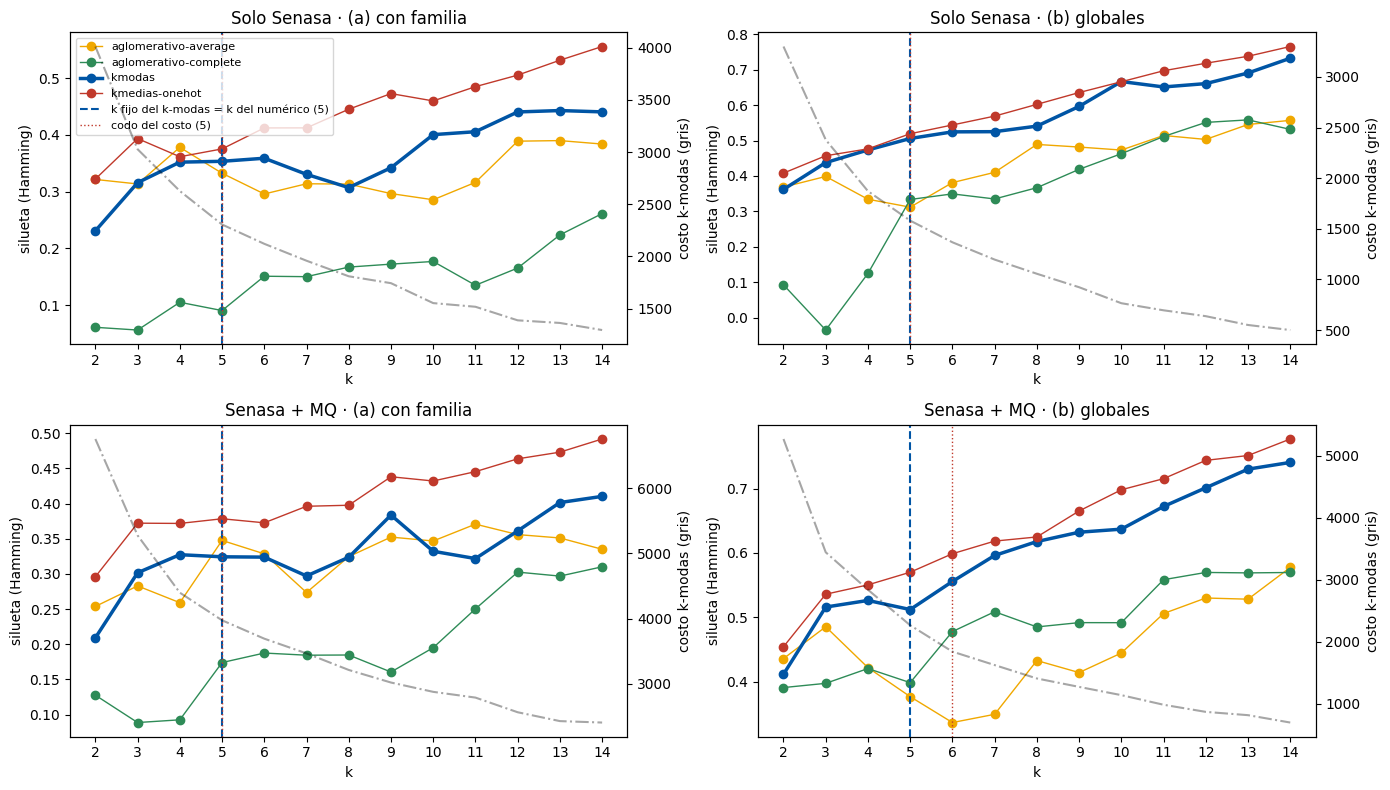

In [5]:
for v, a in A.items():
    for clave, d in a["var"].items():
        b = d["barrido"]
        print(f"{CC.VERSIONES[v]} · variante ({clave}) {d['nombre']} · k del k-modas (fijo) = {d['k_opt']} (k del numérico = {a['K']}) · "
              f"k de mayor silueta = {d['k_sil']} (borde del rango: {CC.KS[-1]}) · codo del costo = {d['k_codo']} · perfiles distintos {d['perfiles']}")
        tab = b.pivot(index="k", columns="metodo", values="silueta_hamming").round(3)
        tab["grupo mínimo (k-modas)"] = b[b["metodo"] == "kmodas"].set_index("k")["grupo_min"]
        tab["costo k-modas"] = b[b["metodo"] == "kmodas"].set_index("k")["costo_kmodas"].astype(int)
        tab["baja del costo"] = tab["costo k-modas"].diff()
        display(tab.style.apply(lambda f: ["font-weight: bold" if f.name == d["k_opt"] else "" for _ in f], axis=1))
        sil, kf = tab["kmodas"], d["k_opt"]
        print(f"   k-modas: silueta {sil[kf - 1]:.3f} (k = {kf - 1}) → {sil[kf]:.3f} (k = {kf}) → {sil[kf + 1]:.3f} (k = {kf + 1}) · "
              f"baja del costo de {kf - 1} a {kf}: {-tab.loc[kf, 'baja del costo']:.0f}, de {kf} a {kf + 1}: {-tab.loc[kf + 1, 'baja del costo']:.0f}, "
              f"de {kf + 1} a {kf + 2}: {-tab.loc[kf + 2, 'baja del costo']:.0f} · grupo mínimo con k = {kf}: {int(tab.loc[kf, 'grupo mínimo (k-modas)'])} muestras "
              f"({100 * tab.loc[kf, 'grupo mínimo (k-modas)'] / len(a['t']):.1f} %)")

fig, ejes = plt.subplots(2, 2, figsize=(14, 8))
for fila, (v, a) in enumerate(A.items()):
    for col, (clave, d) in enumerate(a["var"].items()):
        ax = ejes[fila, col]; b = d["barrido"]
        for m, color in zip(CC.METODOS, [AMBAR, VERDE, AZUL, ROJO]):
            s = b[b["metodo"] == m]
            ax.plot(s["k"], s["silueta_hamming"], marker="o", color=color, label=m, lw=2.5 if m == "kmodas" else 1)
        if a["K"] == d["k_opt"]:
            ax.axvline(d["k_opt"], color=AZUL, ls="--", label=f"k fijo del k-modas = k del numérico ({d['k_opt']})")
        else:
            ax.axvline(a["K"], color="gray", ls=":", label=f"k del numérico ({a['K']})"); ax.axvline(d["k_opt"], color=AZUL, ls="--", label=f"k fijo del k-modas ({d['k_opt']})")
        ax.axvline(d["k_codo"], color=ROJO, ls=":", lw=1, label=f"codo del costo ({d['k_codo']})")
        ax.set_xticks(CC.KS)
        ax2 = ax.twinx(); s = b[b["metodo"] == "kmodas"]
        ax2.plot(s["k"], s["costo_kmodas"], color="black", alpha=0.35, ls="-."); ax2.set_ylabel("costo k-modas (gris)")
        ax.set_title(f"{CC.VERSIONES[v]} · ({clave}) {d['nombre']}"); ax.set_xlabel("k"); ax.set_ylabel("silueta (Hamming)")
ejes[0, 0].legend(fontsize=8)
plt.tight_layout(); plt.show()

### Estabilidad con k = 5
El k-modas con la variante (b) y k = 5, corrido con cinco semillas distintas (`CC.estabilidad`): costo, grupo más chico y
**ARI entre todos los pares de corridas** (1 = misma partición). Si el costo es el mismo pero el ARI no llega a 1, hay
varias particiones empatadas en costo (muestras que están a la misma distancia de dos modas y van a una u otra).
Debajo, qué cambia de una semilla a otra con k = 5: los clusters que salen MIXTO y a qué cluster va la mayoría de los DDL
heladeros. **Los conteos por cluster de este cuaderno valen para la semilla 42** (la de `SEMILLA`): con otra semilla los
totales por tag del numérico no cambian, pero la composición de los clusters que mezclan productos sí.

In [6]:
ESTAB, HEL_SEM = {}, {}
for v, a in A.items():
    tab, aris = CC.estabilidad(a["var"]["b"]["X"])
    ESTAB[v] = (tab, aris)
    print(f"{CC.VERSIONES[v]} · variante (b), k = {CC.K_KMODAS}, {CC.N_INIT} reinicios · ARI entre corridas: mínimo {aris.min():.2f} · "
          f"media {aris.mean():.2f} · máximo {aris.max():.2f}")
    display(tab.set_index("semilla").T)
    # qué cambia entre semillas: los clusters MIXTO y dónde caen los DDL heladeros (dependen de la partición exacta)
    t, X = a["t"], a["var"]["b"]["X"]
    hel = (t["subtipo_eval"] == "DDL heladero").values
    filas = []
    for sem in tab["semilla"]:
        et, _, _ = CC.kmodas(X, CC.K_KMODAS, semilla=int(sem))
        _, tags_ = CC.perfil(t, et, a["var"]["b"]["cols"])
        cuenta = pd.Series(et[hel]).value_counts()
        filas.append({"semilla": sem, "clusters MIXTO": ", ".join(sorted(x for x in tags_.values() if x.startswith("MIXTO"))) or "-",
                      "heladeros en el cluster con más": f"{int(cuenta.iloc[0])} de {int(hel.sum())} ({tags_[cuenta.index[0]]})"})
    HEL_SEM[v] = pd.DataFrame(filas).set_index("semilla")
    display(HEL_SEM[v])

Solo Senasa · variante (b), k = 5, 1000 reinicios · ARI entre corridas: mínimo 0.80 · media 0.84 · máximo 0.99


semilla,42,1,2,3,4
costo,1581,1581,1581,1581,1581
grupo mínimo,382,361,367,418,430


,clusters MIXTO,heladeros en el cluster con más
semilla,,
42,MIXTO_POLVO_MAGRO,104 de 152 (DDL)
1,MIXTO_POLVO_MAGRO,144 de 152 (MIXTO_POLVO_MAGRO)
2,MIXTO_POLVO_MAGRO,144 de 152 (MIXTO_POLVO_MAGRO)
3,MIXTO_POLVO_MAGRO,133 de 152 (MIXTO_POLVO_MAGRO)
4,MIXTO_POLVO_MAGRO,94 de 152 (DDL_2)


Senasa + MQ · variante (b), k = 5, 1000 reinicios · ARI entre corridas: mínimo 0.66 · media 0.78 · máximo 1.00


semilla,42,1,2,3,4
costo,2262,2262,2262,2262,2262
grupo mínimo,582,557,537,557,587


,clusters MIXTO,heladeros en el cluster con más
semilla,,
42,MIXTO_ALTA_HUMEDAD,110 de 175 (POLVO_GRASO)
1,MIXTO_ALTA_HUMEDAD,110 de 175 (POLVO_GRASO)
2,"MIXTO_ALTA_HUMEDAD, MIXTO_POLVO_MAGRO",165 de 175 (MIXTO_POLVO_MAGRO)
3,MIXTO_ALTA_HUMEDAD,110 de 175 (POLVO_GRASO)
4,MIXTO_ALTA_HUMEDAD,97 de 175 (DDL)


## 4 · Tabla comparativa
Para cada versión: el numérico, y el k-modas en las dos variantes con k = 5 (fijo; es también el k del numérico) y con k = 6 como sensibilidad.

- **silueta propia**: en el espacio con el que se armó (euclídea escalada para el numérico; Hamming sobre sus
  categorías para el categórico). **Macro**: el promedio de la silueta media de cada grupo (un grupo chico pesa igual
  que uno grande).
- **silueta en el otro espacio**: el numérico medido con Hamming sobre las categorías de la variante (a o b, según la
  fila de comparación) y el categórico medido con euclídea sobre los análisis escalados.
- **ARI / NMI familia**: solo muestras con familia conocida (acá todas la traen; la de las solo MQ sale de MQ encolumnado, que la asigna un modelo).
- **ARI / NMI subtipo**: DDL familiar / repostero / heladero y la clase de humedad del CAA en el queso (los quesos de la rama propia no
  entran; quedan unos pocos con familia queso en Senasa + MQ, los que el catálogo no confirma: sección 7); **subtipo DDL**: lo mismo, solo dentro del dulce de leche.
- **ARI / NMI con el numérico**: acuerdo entre la partición categórica y la numérica (1 = idénticas, 0 = al azar).
- La fila **«+ subtags del DDL»** es el numérico con el segundo nivel de las secciones 3 y 4 (`subtag` de
  `clusters_*.csv`: DDL_HELADERO, DDL_FAMILIAR, DDL_REPOSTERO y el resto del DDL como DDL). Su silueta es baja a propósito: los subtags
  son un segundo nivel dentro del DDL, no grupos del primero; lo que importa de esa fila es el ARI contra el subtipo.

Una silueta propia **no es comparable** entre los dos espacios (Hamming y euclídea miden cosas distintas); la silueta
en el espacio del otro sí lo es dentro de cada espacio.

In [7]:
filas = []
for v, a in A.items():
    t, Z = a["t"], a["Z"]
    for clave, d in a["var"].items():
        m = CC.metricas(t, a["et_num"], Z, d["X"], "euclidea")
        filas.append({"versión": CC.VERSIONES[v], "algoritmo": f"k-medias numérico (otro espacio = Hamming {clave})",
                      **m, "ARI con el numérico": 1.0, "NMI con el numérico": 1.0})
    et_sub = pd.factorize(t["subtag"])[0]          # el numérico con el segundo nivel del DDL (DDL_HELADERO, DDL_FAMILIAR)
    m = CC.metricas(t, et_sub, Z, a["var"]["b"]["X"], "euclidea")
    filas.append({"versión": CC.VERSIONES[v], "algoritmo": "k-medias numérico + subtags del DDL (otro espacio = Hamming b)",
                  **m, "ARI con el numérico": adjusted_rand_score(a["et_num"], et_sub),
                  "NMI con el numérico": normalized_mutual_info_score(a["et_num"], et_sub)})
    for clave, d in a["var"].items():
        for k in ks_de(a, d):
            et = d["part"][("kmodas", k)]
            m = CC.metricas(t, et, Z, d["X"], "hamming")
            filas.append({"versión": CC.VERSIONES[v],
                          "algoritmo": f"k-modas ({clave}) {d['nombre']}, k = {k} " + rotulo(k, a, d),
                          **m, "ARI con el numérico": adjusted_rand_score(a["et_num"], et),
                          "NMI con el numérico": normalized_mutual_info_score(a["et_num"], et)})
comparacion = pd.DataFrame(filas).set_index(["versión", "algoritmo"])
# las dos filas del numérico solo difieren en la silueta en el otro espacio
comparacion.round(3)

k  silueta propia  silueta macro propia  silueta en el otro espacio  \
versión     algoritmo                                                                                                                  
Solo Senasa k-medias numérico (otro espacio = Hamming a)         5           0.854                 0.760                       0.062   
            k-medias numérico (otro espacio = Hamming b)         5           0.854                 0.760                       0.145   
            k-medias numérico + subtags del DDL (otro espac...  14           0.227                 0.452                      -0.060   
            k-modas (a) con familia, k = 5 (fijo; = k del n...   5           0.354                 0.371                      -0.094   
            k-modas (a) con familia, k = 6 (sensibilidad)        6           0.359                 0.377                      -0.118   
            k-modas (b) globales, k = 5 (fijo; = k del numé...   5           0.506                 0.510                       0.082   
            k-modas (b) globales, k = 6 (sensibilidad)           6           0.525                 0.521                       0.045   
Senasa + MQ k-medias numérico (otro espacio = Hamming a)         5           0.835                 0.754                       0.133   
            k-medias numérico (otro espacio = Hamming b)         5           0.835                 0.754                       0.328   
            k-medias numérico + subtags del DDL (otro espac...  13           0.371                 0.341                       0.110   
            k-modas (a) con familia, k = 5 (fijo; = k del n...   5           0.324                 0.357                      -0.014   
            k-modas (a) con familia, k = 6 (sensibilidad)        6           0.324                 0.339                       0.002   
            k-modas (b) globales, k = 5 (fijo; = k del numé...   5           0.512                 0.531                       0.186   
            k-modas (b) globales, k = 6 (sensibilidad)           6           0.556                 0.557                       0.147   

                                                                silueta macro en el otro espacio  ARI familia  NMI familia  ARI subtipo  NMI subtipo  \
versión     algoritmo                                                                                                                                  
Solo Senasa k-medias numérico (otro espacio = Hamming a)                                   0.169        0.968        0.839       -0.000        0.001   
            k-medias numérico (otro espacio = Hamming b)                                   0.338        0.968        0.839       -0.000        0.001   
            k-medias numérico + subtags del DDL (otro espac...                            -0.143        0.225        0.523        0.527        0.536   
            k-modas (a) con familia, k = 5 (fijo; = k del n...                            -0.100        0.006        0.015        0.133        0.230   
            k-modas (a) con familia, k = 6 (sensibilidad)                                 -0.138        0.007        0.020        0.149        0.243   
            k-modas (b) globales, k = 5 (fijo; = k del numé...                             0.072        0.119        0.336        0.174        0.231   
            k-modas (b) globales, k = 6 (sensibilidad)                                     0.027        0.066        0.283        0.201        0.253   
Senasa + MQ k-medias numérico (otro espacio = Hamming a)                                   0.199        0.921        0.762        0.038        0.130   
            k-medias numérico (otro espacio = Hamming b)                                   0.370        0.921        0.762        0.038        0.130   
            k-medias numérico + subtags del DDL (otro espac...                            -0.163        0.372        0.627        0.527        0.560   
            k-modas (a) con familia, k = 5 (fijo; = k del n...  

## 5 · Tags numéricos contra clusters categóricos
Tabla cruzada con k = 5 (fijo; el del numérico) y con k = 6 (sensibilidad): filas = tag del k-medias, columnas = cluster del k-modas
(numerado por tamaño, 0 = el más grande). Si las dos particiones coincidieran, cada fila tendría una sola celda llena.

In [8]:
for v, a in A.items():
    for clave, d in a["var"].items():
        for k in ks_de(a, d):
            et = d["part"][("kmodas", k)]
            print(f"{CC.VERSIONES[v]} · variante ({clave}) {d['nombre']} · k = {k} {rotulo(k, a, d)}")
            display(pd.crosstab(pd.Series(a["t"]["tag_num"].values, name="tag numérico"), pd.Series(et, name="cluster categórico"), margins=True, margins_name="total"))

Solo Senasa · variante (a) con familia · k = 5 (fijo; = k del numérico)


cluster categórico,0,1,2,3,4,total
tag numérico,,,,,,
DDL,555,467,447,420,227,2116
LIQUIDO,1,4,0,5,0,10
POLVO_GRASO,34,33,9,11,0,87
POLVO_MAGRO,83,79,80,45,48,335
PROT_ALTA,2,0,0,1,46,49
total,675,583,536,482,321,2597


Solo Senasa · variante (a) con familia · k = 6 (sensibilidad)


cluster categórico,0,1,2,3,4,5,total
tag numérico,,,,,,,
DDL,447,443,383,321,295,227,2116
LIQUIDO,0,1,1,4,4,0,10
POLVO_GRASO,9,22,29,16,11,0,87
POLVO_MAGRO,80,26,77,59,45,48,335
PROT_ALTA,0,2,0,0,1,46,49
total,536,494,490,400,356,321,2597


Solo Senasa · variante (b) globales · k = 5 (fijo; = k del numérico)


cluster categórico,0,1,2,3,4,total
tag numérico,,,,,,
DDL,587,568,87,506,368,2116
LIQUIDO,2,0,0,0,8,10
POLVO_GRASO,0,0,87,0,0,87
POLVO_MAGRO,0,0,329,0,6,335
PROT_ALTA,0,0,49,0,0,49
total,589,568,552,506,382,2597


... (6 outputs left out)

Senasa + MQ · variante (b) globales · k = 5 (fijo; = k del numérico)


cluster categórico,0,1,2,3,4,total
tag numérico,,,,,,
DDL,985,204,340,120,577,2226
LIQUIDO,6,16,424,3,5,454
POLVO_GRASO,0,644,0,0,0,644
POLVO_MAGRO,0,20,0,426,0,446
PROT_ALTA,0,10,0,56,0,66
total,991,894,764,605,582,3836


Senasa + MQ · variante (b) globales · k = 6 (sensibilidad)


cluster categórico,0,1,2,3,4,5,total
tag numérico,,,,,,,
DDL,389,280,43,531,535,448,2226
LIQUIDO,436,3,5,5,0,5,454
POLVO_GRASO,0,0,644,0,0,0,644
POLVO_MAGRO,0,431,15,0,0,0,446
PROT_ALTA,0,66,0,0,0,0,66
total,825,780,707,536,535,453,3836


## 6 · Perfil y tag de cada cluster categórico
Por cluster (k = 5, el fijo y el del numérico; y k = 6 como sensibilidad): categoría modal de cada análisis y qué fracción del grupo la tiene, familia
mayoritaria (entre las de familia conocida), tag numérico mayoritario y el centroide numérico en g/100 g (la media de
los análisis originales de las muestras del grupo, que el algoritmo **no** vio). El **tag** sale de ese centroide con
las mismas reglas que el numérico (`etiquetar()`: DDL, POLVO_GRASO, POLVO_MAGRO, PROT_ALTA, LIQUIDO, QUESO,
ALTA_HUMEDAD; si dos grupos caen en la misma regla, el de menor humedad y grasa conserva el nombre y el otro lleva `_2`,
`_3`: por ejemplo, los clusters de DDL del k-modas se llaman DDL, DDL_2, DDL_3…). Cuando el grupo junta productos
distintos (el tag numérico mayoritario cubre menos del 60 %), el centroide es un promedio sin sentido físico y el grupo
se rotula **`MIXTO_<tag>`** (por ejemplo líquidos con dulce de leche, o polvos magros con dulce de leche), para no hacer
pasar por un producto un grupo que no lo es. Había también un tag `POLVO` para los grupos que mezclaban solo polvos;
no apareció en ninguna de las 52 particiones probadas (2 versiones × 2 cortes × k de 2 a 14) y se quitó.

In [9]:
PERFILES, TAGS_CAT = {}, {}
for v, a in A.items():
    for clave, d in a["var"].items():
        for k in ks_de(a, d):
            et = d["part"][("kmodas", k)]
            p, _ = CC.perfil(a["t"], et, d["cols"])
            PERFILES[(v, clave, k)] = p; TAGS_CAT[(v, clave, k)] = p["tag"].to_dict()
            print(f"{CC.VERSIONES[v]} · variante ({clave}) {d['nombre']} · k = {k} {rotulo(k, a, d)}")
            display(p)

Solo Senasa · variante (a) con familia · k = 5 (fijo; = k del numérico)


,tag,muestras,humedad,materia_grasa,proteinas,cenizas,familia mayoritaria,sin familia,tag numérico mayoritario,humedad (g/100 g),grasa (g/100 g),proteinas (g/100 g),cenizas (g/100 g)
cluster,,,,,,,,,,,,,
0,DDL_4,675,medio (89 %),dulce de leche (79 %),medio (67 %),medio (67 %),dulce de leche (82 %),0,DDL (82 %),23.47,7.36,10.69,2.19
1,DDL_3,583,bajo (51 %),dulce de leche (67 %),bajo (92 %),bajo (93 %),dulce de leche (80 %),0,DDL (80 %),22.95,7.19,10.23,1.99
2,DDL,536,bajo (71 %),dulce de leche (74 %),alto (86 %),alto (76 %),dulce de leche (83 %),0,DDL (83 %),21.70,7.04,12.03,2.74
3,DDL_5,482,alto (100 %),dulce de leche (81 %),medio (70 %),medio (71 %),dulce de leche (88 %),0,DDL (87 %),26.91,6.92,8.87,1.95
4,DDL_2,321,alto (100 %),dulce de leche (55 %),alto (96 %),alto (85 %),dulce de leche (71 %),0,DDL (71 %),22.65,6.36,22.99,3.00


Solo Senasa · variante (a) con familia · k = 6 (sensibilidad)


,tag,muestras,humedad,materia_grasa,proteinas,cenizas,familia mayoritaria,sin familia,tag numérico mayoritario,humedad (g/100 g),grasa (g/100 g),proteinas (g/100 g),cenizas (g/100 g)
cluster,,,,,,,,,,,,,
0,DDL,536,bajo (71 %),dulce de leche (74 %),alto (86 %),alto (76 %),dulce de leche (83 %),0,DDL (83 %),21.70,7.04,12.03,2.74
1,DDL_5,494,medio (65 %),dulce de leche (83 %),medio (70 %),bajo (100 %),dulce de leche (90 %),0,DDL (90 %),25.80,7.35,8.52,1.67
2,DDL_2,490,medio (85 %),dulce de leche (74 %),medio (56 %),medio (92 %),dulce de leche (78 %),0,DDL (78 %),22.41,7.47,11.59,2.43
3,DDL_4,400,bajo (63 %),dulce de leche (69 %),bajo (100 %),bajo (90 %),dulce de leche (81 %),0,DDL (80 %),23.06,6.81,10.07,1.97
4,DDL_6,356,alto (100 %),dulce de leche (76 %),medio (59 %),medio (96 %),dulce de leche (83 %),0,DDL (83 %),25.98,7.00,9.93,2.18
5,DDL_3,321,alto (100 %),dulce de leche (55 %),alto (96 %),alto (85 %),dulce de leche (71 %),0,DDL (71 %),22.65,6.36,22.99,3.00


Solo Senasa · variante (b) globales · k = 5 (fijo; = k del numérico)


,tag,muestras,humedad,materia_grasa,proteinas,cenizas,familia mayoritaria,sin familia,tag numérico mayoritario,humedad (g/100 g),grasa (g/100 g),proteinas (g/100 g),cenizas (g/100 g)
cluster,,,,,,,,,,,,,
0,DDL,589,medio (61 %),medio (81 %),medio (93 %),medio (83 %),dulce de leche (100 %),0,DDL (100 %),27.23,7.01,6.31,1.70
1,DDL_3,568,medio (70 %),medio (85 %),alto (100 %),medio (73 %),dulce de leche (100 %),0,DDL (100 %),28.45,7.93,7.73,1.77
2,MIXTO_POLVO_MAGRO,552,bajo (99 %),bajo (75 %),alto (98 %),alto (97 %),concentrado proteico (59 %),0,POLVO_MAGRO (60 %),7.26,7.19,33.00,5.15
3,DDL_4,506,medio (92 %),medio (80 %),medio (70 %),bajo (100 %),dulce de leche (100 %),0,DDL (100 %),28.46,6.77,5.86,1.30
4,DDL_2,382,bajo (57 %),bajo (92 %),bajo (95 %),bajo (95 %),dulce de leche (97 %),0,DDL (96 %),27.48,5.99,5.23,1.31


... (6 outputs left out)

Senasa + MQ · variante (b) globales · k = 5 (fijo; = k del numérico)


,tag,muestras,humedad,materia_grasa,proteinas,cenizas,familia mayoritaria,sin familia,tag numérico mayoritario,humedad (g/100 g),grasa (g/100 g),proteinas (g/100 g),cenizas (g/100 g)
cluster,,,,,,,,,,,,,
0,DDL,991,medio (84 %),medio (82 %),medio (82 %),bajo (57 %),dulce de leche (99 %),0,DDL (99 %),28.55,6.93,6.08,1.40
1,POLVO_GRASO,894,bajo (92 %),alto (80 %),alto (88 %),alto (97 %),leche en polvo (67 %),0,POLVO_GRASO (72 %),9.16,22.08,21.63,4.76
2,MIXTO_ALTA_HUMEDAD,764,alto (58 %),bajo (100 %),bajo (90 %),bajo (99 %),dulce de leche (45 %),0,LIQUIDO (55 %),60.89,3.09,4.21,0.96
3,POLVO_MAGRO,605,bajo (97 %),bajo (100 %),alto (89 %),alto (89 %),concentrado proteico (56 %),0,POLVO_MAGRO (70 %),8.60,3.18,31.80,5.14
4,DDL_2,582,medio (73 %),medio (87 %),alto (92 %),medio (85 %),dulce de leche (99 %),0,DDL (99 %),28.71,7.64,7.46,1.73


Senasa + MQ · variante (b) globales · k = 6 (sensibilidad)


,tag,muestras,humedad,materia_grasa,proteinas,cenizas,familia mayoritaria,sin familia,tag numérico mayoritario,humedad (g/100 g),grasa (g/100 g),proteinas (g/100 g),cenizas (g/100 g)
cluster,,,,,,,,,,,,,
0,MIXTO_ALTA_HUMEDAD,825,alto (55 %),bajo (95 %),bajo (89 %),bajo (96 %),dulce de leche (47 %),0,LIQUIDO (53 %),59.05,3.39,4.35,0.99
1,MIXTO_POLVO_MAGRO,780,bajo (96 %),bajo (78 %),alto (79 %),alto (91 %),concentrado proteico (44 %),0,POLVO_MAGRO (55 %),11.62,4.13,27.33,4.56
2,POLVO_GRASO,707,bajo (94 %),alto (100 %),alto (99 %),alto (99 %),leche en polvo (85 %),0,POLVO_GRASO (91 %),4.96,25.88,24.27,5.36
3,DDL_3,536,medio (72 %),medio (90 %),alto (100 %),medio (83 %),dulce de leche (99 %),0,DDL (99 %),28.75,7.77,7.63,1.75
4,DDL,535,medio (93 %),medio (78 %),medio (71 %),bajo (100 %),dulce de leche (100 %),0,DDL (100 %),28.50,6.75,5.88,1.30
5,DDL_2,453,medio (77 %),medio (86 %),medio (95 %),medio (98 %),dulce de leche (99 %),0,DDL (99 %),28.63,7.16,6.29,1.54


## 7 · Subtipos: ¿quién separa el dulce de leche familiar, repostero y heladero?
Dentro del dulce de leche con subtipo conocido: la composición media de cada subtipo, y cómo se reparten en los grupos
del numérico (tag y subtag) y del k-modas (k = 5). Los quesos que confirma el catálogo no están en el k-medias; los que quedan con familia queso (solo MQ, sin confirmar por el rótulo) se muestran
aparte.

In [10]:
for v, a in A.items():
    t = a["t"]; ddl = t["subtipo_eval"].str.startswith("DDL", na=False).values
    print(f"{CC.VERSIONES[v]} · DDL con subtipo: {int(ddl.sum())}")
    display(t[ddl].groupby("subtipo_eval")[COLUMNAS].agg(["mean", "std"]).round(2))
    partes = {"numérico (tag)": t["tag_num"].values, "numérico (subtag)": t["subtag"].values}
    for clave, d in a["var"].items():
        partes[f"k-modas ({clave})"] = d["part"][("kmodas", d["k_opt"])]
    tablas = [pd.crosstab(pd.Series(t.loc[ddl, "subtipo_eval"].values, name="subtipo"), pd.Series(np.asarray(e)[ddl], name=n)) for n, e in partes.items()]
    display(pd.concat(tablas, axis=1, keys=list(partes)))
q = A["senasa_mq"]["t"]; q = q[q["familia"] == "queso"]
print("Quesos (Senasa + MQ):")
display(q[["subtipo", "subtipo_eval", "tag_num"] + COLUMNAS].assign(
    **{f"k-modas ({c})": A["senasa_mq"]["var"][c]["part"][("kmodas", CC.K_KMODAS)][q.index] for c in "ab"}))

Solo Senasa · DDL con subtipo: 1516


humedad       grasa       proteinas       cenizas      
                 mean   std  mean   std      mean   std    mean   std
subtipo_eval                                                         
DDL familiar    28.73  1.88  6.78  0.72      5.90  0.55    1.37  0.16
DDL heladero    22.40  2.19  6.74  0.80      6.67  0.54    2.49  0.30
DDL repostero   26.64  3.10  7.01  1.02      6.46  1.06    1.48  0.25

numérico (tag)         numérico (subtag)                                                 k-modas (a)                    k-modas (b)           \
                         DDL LIQUIDO               DDL DDL_FAMILIAR DDL_HELADERO DDL_REPOSTERO LIQUIDO           0    1    2    3   4           0    1   2   
subtipo                                                                                                                                                      
DDL familiar             749       1               145          564            1            39       1         228  225   13  267  17         223   29   3   
DDL heladero             152       0                 5            0          146             1       0           7    0  138    0   7         104    0  41   
DDL repostero            612       2               120           43            3           446       2         183  205  193   26   7         126  215  26   

                         
                 3    4  
subtipo                  
DDL familiar   376  119  
DDL heladero     0    7  
DDL repostero   45  202

Senasa + MQ · DDL con subtipo: 1596


humedad       grasa       proteinas       cenizas      
                 mean   std  mean   std      mean   std    mean   std
subtipo_eval                                                         
DDL familiar    28.77  1.87  6.67  1.03      5.90  0.56    1.37  0.17
DDL heladero    22.46  2.20  6.54  0.99      6.72  0.59    2.51  0.32
DDL repostero   26.65  3.08  7.00  1.02      6.47  1.08    1.48  0.26

numérico (tag)         numérico (subtag)                                                 k-modas (a)                   k-modas (b)            \
                         DDL LIQUIDO               DDL DDL_FAMILIAR DDL_HELADERO DDL_REPOSTERO LIQUIDO           0    1   2   3    4           0    1    2   
subtipo                                                                                                                                                      
DDL familiar             789       1               165          584            2            38       1         382  355  47   0    6         606    4  125   
DDL heladero             175       0                 8            1          165             1       0           8    7   1   1  158           8  110    0   
DDL repostero            629       2               129           44            2           454       2         219  187  52  12  161         164   29  174   

                        
                3    4  
subtipo                 
DDL familiar    9   46  
DDL heladero   55    2  
DDL repostero  43  221

Quesos (Senasa + MQ):


,subtipo,subtipo_eval,tag_num,humedad,grasa,proteinas,cenizas,k-modas (a),k-modas (b)
3005,NaN,queso muy alta humedad,LIQUIDO,72.26,14.54,5.80,1.18,0,0
3121,NaN,queso muy alta humedad,LIQUIDO,73.85,7.38,11.23,1.34,0,0
3303,NaN,queso muy alta humedad,LIQUIDO,70.97,12.71,6.60,1.50,1,1
3304,NaN,queso muy alta humedad,LIQUIDO,81.75,6.23,6.24,1.08,0,2
3305,NaN,queso muy alta humedad,LIQUIDO,68.73,13.49,9.95,1.30,0,1
3306,NaN,queso muy alta humedad,LIQUIDO,74.19,7.24,10.29,1.38,0,0
3307,NaN,queso muy alta humedad,LIQUIDO,75.37,7.97,7.61,1.70,1,4
3308,NaN,queso muy alta humedad,LIQUIDO,75.98,7.17,7.21,1.57,1,4
3347,NaN,queso muy alta humedad,LIQUIDO,72.24,10.69,6.61,1.71,1,1
3348,NaN,queso muy alta humedad,LIQUIDO,73.00,11.92,7.05,1.49,1,1


## 8 · Control: otros algoritmos categóricos
¿El resultado es del k-modas o de las categorías? Con k = 5: aglomerativo con Hamming (`average` y
`complete`) y k-medias sobre one-hot, contra el k-modas y contra el numérico. Si los cuatro dan ARI parecidos contra la
familia y contra el numérico, la conclusión depende de la codificación, no del algoritmo.

In [11]:
filas = []
for v, a in A.items():
    for clave, d in a["var"].items():
        ref = d["part"][("kmodas", d["k_opt"])]
        for m in CC.METODOS:
            et = d["part"][(m, d["k_opt"])]
            ari_f, _ = CC.contra(et, a["t"]["familia"].where(a["t"]["familia_conocida"]))
            ari_s, _ = CC.contra(et, a["t"]["subtipo_eval"])
            filas.append({"versión": CC.VERSIONES[v], "variante": f"({clave}) {d['nombre']}", "método": m,
                          "silueta Hamming": d["barrido"].set_index(["metodo", "k"]).loc[(m, d["k_opt"]), "silueta_hamming"],
                          "grupo mínimo": int(np.bincount(et).min()),
                          "ARI con k-modas": adjusted_rand_score(ref, et), "ARI con el numérico": adjusted_rand_score(a["et_num"], et),
                          "ARI familia": ari_f, "ARI subtipo": ari_s})
CONTROL = pd.DataFrame(filas).set_index(["versión", "variante", "método"])
CONTROL.round(3)

silueta Hamming  grupo mínimo  ARI con k-modas  ARI con el numérico  ARI familia  ARI subtipo
versión     variante        método                                                                                                              
Solo Senasa (a) con familia aglomerativo-average             0.332             7            0.336                0.025        0.023        0.155
                            aglomerativo-complete            0.090           188            0.203               -0.013       -0.009        0.174
                            kmodas                           0.354           321            1.000                0.007        0.006        0.133
                            kmedias-onehot                   0.375           366            0.428               -0.008       -0.011        0.145
            (b) globales    aglomerativo-average             0.312             3            0.302                0.041        0.038        0.178
                            aglomerativo-complete            0.334            21            0.392                0.193        0.192        0.124
                            kmodas                           0.506           382            1.000                0.120        0.119        0.174
                            kmedias-onehot                   0.519           390            0.917                0.102        0.101        0.171
Senasa + MQ (a) con familia aglomerativo-average             0.348             7            0.399                0.062        0.054        0.171
                            aglomerativo-complete            0.174           395            0.193                0.037        0.028        0.271
                            kmodas                           0.324           484            1.000                0.115        0.101        0.139
                            kmedias-onehot                   0.378           540            0.551                0.132        0.122        0.189
            (b) globales    aglomerativo-average             0.377            47            0.425                0.164        0.128        0.183
                            aglomerativo-complete            0.399           427            0.391                0.180        0.140        0.278
                            kmodas                           0.512           582            1.000                0.326        0.260        0.301
                            kmedias-onehot                   0.570           596            0.659                0.322        0.258        0.121

## 9 · Extra: el categórico admite muestras incompletas («no medido»)
El k-medias necesita los cuatro análisis. Con categorías, un análisis que falta puede ser una categoría más,
**«no medido»**. `CC.cargar_ampliado` toma, además de las muestras del k-medias, las que tienen entre 1 y 3 de los
cuatro análisis (sin las excluidas por humedad + sólidos). Para el clustering se piden **al menos 2 de 4** (con uno
solo, la muestra es casi toda «no medido»). Se corre el k-modas con k = 5 y se mira (i) cuántas muestras más
entran, (ii) si las muestras completas quedan agrupadas como sin las incompletas (ARI) y (iii) cuánto se agrupa por
«qué se midió» en vez de por composición (un grupo con «no medido» como moda es un grupo armado por el patrón de
faltantes, no por el producto).

In [12]:
AMPLIADO, CONTEOS, AMP_ARI = {}, {}, {}
for v, a in A.items():
    amp, conteo = CC.cargar_ampliado(v)
    CONTEOS[v] = conteo
    print(f"{CC.VERSIONES[v]} · muestras por cantidad de análisis medidos (de humedad, grasa, proteínas, cenizas):")
    display(conteo)
    print(f"   entran con ≥ 2 de 4: {len(amp)} ({int(amp['completa'].sum())} completas + {int((~amp['completa']).sum())} incompletas, "
          f"×{len(amp) / amp['completa'].sum():.1f})")
    for clave, (nombre, cols) in CC.VARIANTES.items():
        X, _ = CC.codificar(amp, cols)
        et, _, _ = CC.kmodas(X, CC.K_KMODAS)
        AMPLIADO[(v, clave)] = (amp, et)
        sel = amp["completa"].values
        base = pd.Series(a["var"][clave]["part"][("kmodas", CC.K_KMODAS)], index=a["t"]["Identificador"])
        ari_c = adjusted_rand_score(base[amp.loc[sel, "Identificador"]].values, et[sel])
        ari_f, _ = CC.contra(et, amp["familia"].where(amp["familia"] != CC.SIN_FAMILIA))
        no_med = amp[cols].eq(CC.NO_MEDIDO).groupby(et).mean().round(2)
        no_med.columns = [c.split("_", 1)[1] for c in cols]
        AMP_ARI[(v, clave)] = ari_c
        print(f"   variante ({clave}) {nombre}: ARI de las completas contra el k-modas sin incompletas {ari_c:.2f} · ARI familia {ari_f:.2f}")
        display(no_med.assign(muestras=np.bincount(et), familia_mayoritaria=amp.groupby(et)["familia"].agg(lambda s: s.value_counts().index[0]))
                .rename_axis("cluster").add_prefix("").rename(columns=lambda c: c if c in ("muestras", "familia_mayoritaria") else f"% no medido {c}"))

Solo Senasa · muestras por cantidad de análisis medidos (de humedad, grasa, proteínas, cenizas):


análisis medidos (de 4),1,2,3,4,total
row_0,,,,,
completa (k-medias),0,7,0,2590,2597
incompleta,1151,367,701,0,2219
total,1151,374,701,2590,4816


   entran con ≥ 2 de 4: 3665 (2597 completas + 1068 incompletas, ×1.4)


   variante (a) con familia: ARI de las completas contra el k-modas sin incompletas 0.57 · ARI familia 0.03


,% no medido humedad,% no medido materia_grasa,% no medido proteinas,% no medido cenizas,muestras,familia_mayoritaria
cluster,,,,,,
0,0.04,0.01,0.01,0.13,1128,dulce de leche
1,0.03,0.00,0.00,0.06,929,dulce de leche
2,0.04,0.00,0.00,0.05,871,dulce de leche
3,0.00,0.00,0.73,1.00,463,dulce de leche
4,0.99,0.00,0.00,0.03,274,dulce de leche


   variante (b) globales: ARI de las completas contra el k-modas sin incompletas 0.69 · ARI familia 0.13


... (4 outputs left out)

   variante (a) con familia: ARI de las completas contra el k-modas sin incompletas 0.47 · ARI familia 0.15


,% no medido humedad,% no medido materia_grasa,% no medido proteinas,% no medido cenizas,muestras,familia_mayoritaria
cluster,,,,,,
0,0.09,0.09,0.06,0.15,2447,dulce de leche
1,0.61,0.05,0.20,0.13,2238,dulce de leche
2,0.01,0.03,0.73,0.80,1958,queso
3,0.03,0.05,0.60,0.52,1403,leche en polvo
4,0.10,0.04,0.00,0.03,1171,dulce de leche


   variante (b) globales: ARI de las completas contra el k-modas sin incompletas 0.55 · ARI familia 0.32


,% no medido humedad,% no medido materia_grasa,% no medido proteinas,% no medido cenizas,muestras,familia_mayoritaria
cluster,,,,,,
0,0.00,0.04,0.26,0.14,2232,leche en polvo
1,0.03,0.07,0.81,0.94,2045,queso
2,0.03,0.00,0.00,0.11,1929,dulce de leche
3,0.10,0.00,0.16,0.23,1516,dulce de leche
4,1.00,0.18,0.26,0.14,1495,sin clasificar


## 10 · Guardar
`resultados/comparacion_num_cat/comparacion_<version>.csv`: una fila por muestra del k-medias, con Identificador,
familia, subtipo, origen, tag numérico y, para cada variante y k (el fijo, 5; el del numérico, si es otro; y 6 como sensibilidad), el cluster categórico y su tag.
Además la tabla comparativa (`tabla_comparativa.csv`) y los perfiles (`perfiles_<version>.csv`).

In [13]:
CC.SALIDA.mkdir(parents=True, exist_ok=True)
for v, a in A.items():
    t = a["t"].copy(); cols = []
    for clave, d in a["var"].items():
        for k in ks_de(a, d):
            et = d["part"][("kmodas", k)]; nom = f"{clave}_k{k}"
            t[f"cluster_cat_{nom}"] = et; t[f"tag_cat_{nom}"] = [TAGS_CAT[(v, clave, k)][g] for g in et]
            cols += [f"cluster_cat_{nom}", f"tag_cat_{nom}"]
    ruta = CC.guardar(t, cols, v)
    pd.concat({f"({c}) k={k}": p for (vv, c, k), p in PERFILES.items() if vv == v}, names=["variante", "cluster"]).to_csv(
        CC.SALIDA / f"perfiles_{v}.csv", encoding="utf-8-sig")
    print("Guardado:", ruta.relative_to(R.RAIZ), pd.read_csv(ruta).shape)
comparacion.round(4).to_csv(CC.SALIDA / "tabla_comparativa.csv", encoding="utf-8-sig")
print("Guardado:", (CC.SALIDA / "tabla_comparativa.csv").relative_to(R.RAIZ))

Guardado: resultados\comparacion_num_cat\comparacion_senasa.csv (2597, 13)
Guardado: resultados\comparacion_num_cat\comparacion_senasa_mq.csv (3836, 13)
Guardado: resultados\comparacion_num_cat\tabla_comparativa.csv


## 11 · Datos usados en cada entrenamiento
Cuántas muestras entran a cada modelo de este cuaderno, con el mismo formato que en los demás (parte II del cuaderno
general). No hay partición en entrenamiento y prueba: son agrupamientos, se entrenan y se evalúan con las mismas
muestras. Los números salen de las variables de arriba, no están escritos a mano. Los modelos que se entrenan son el
k-medias numérico de referencia, el k-modas (variantes a y b, con k = 5 y k = 6 de sensibilidad), los dos controles categóricos
(aglomerativo con Hamming y k-medias sobre one-hot) y el k-modas con «no medido» de la sección 9.

In [14]:
import datos_entrenamiento as DE
from datos_clase41 import N_INIT_KMEDIAS

PART = "sin partición: no supervisado, se entrena y se evalúa con las mismas muestras"
filas, DISP = [], {}
for v, a in A.items():
    cl = pd.read_csv(R.TABLAS / f"clusters_{v}.csv", encoding="utf-8-sig")
    rama = cl["rama"] == "k-medias"
    n_disp, n_usa, n_queso = int(rama.sum()), len(a["t"]), int((~rama).sum())
    assert n_usa == int(cl["cluster"].notna().sum()), "las muestras del cuaderno no son las del k-medias"
    DISP[v] = n_disp
    nom = CC.VERSIONES[v]
    datos = f"{nom}: muestras de la rama k-medias (cuatro análisis completos, suma ≤ 102, lácteas)"
    comun = dict(disponibles=n_disp, usadas=n_usa, motivo=f"{n_disp - n_usa} outliers por consenso del k-medias", particion=PART)
    fuera = f"los {n_queso} quesos de la rama propia no están"
    barrido = f"k de {CC.KS[0]} a {CC.KS[-1]} en las dos variantes"
    filas += [
        DE.fila("II", f"k-medias numérico de referencia, {nom}", datos + ", escaladas",
                nota=f"k = {a['K']}, n_init = {N_INIT_KMEDIAS}, semilla {SEMILLA}; reproduce el del cuaderno principal; {fuera}", **comun),
        DE.fila("II", f"k-modas (a) con familia, {nom}", datos + ", con los cuatro análisis pasados a categorías (cortes por familia)",
                nota=f"k = {CC.K_KMODAS} (fijo; el del numérico es {a['K']}) y k = {K_SENS} (sensibilidad); barrido de {barrido}; {CC.N_INIT} reinicios por corrida", **comun),
        DE.fila("II", f"k-modas (b) globales, {nom}", datos + ", con los cuatro análisis pasados a categorías (cortes «*» globales)",
                nota=f"k = {CC.K_KMODAS} (fijo; el del numérico es {a['K']}) y k = {K_SENS} (sensibilidad); barrido de {barrido}; {CC.N_INIT} reinicios por corrida; "
                     f"estabilidad con {len(ESTAB[v][0])} semillas", **comun),
        DE.fila("II", f"aglomerativo con Hamming (average y complete), {nom}", datos + ", categorías de las variantes (a) y (b)",
                nota=f"control; k = {CC.K_KMODAS} en las tablas y barrido de {barrido}", **comun),
        DE.fila("II", f"k-medias sobre one-hot, {nom}", datos + ", categorías de las variantes (a) y (b) en one-hot",
                nota=f"control; n_init = {N_INIT_KMEDIAS}; k = {CC.K_KMODAS} en las tablas y barrido de {barrido}", **comun),
    ]
    cont, amp = CONTEOS[v], AMPLIADO[(v, "b")][0]
    n_tot, n_amp, n_comp = int(cont.loc["total", "total"]), len(amp), int(amp["completa"].sum())
    filas.append(DE.fila(
        "II", f"k-modas con «no medido» (a) y (b), k = {CC.K_KMODAS}, {nom}",
        f"{nom}: muestras con 1 a 4 de los cuatro análisis (las completas del k-medias y las incompletas, sin las excluidas)",
        n_tot, n_amp, motivo=f"{n_tot - n_amp} con un solo análisis medido (se piden al menos 2 de 4)", particion=PART,
        nota=f"{n_comp} completas + {n_amp - n_comp} incompletas; {n_amp} de {n_tot}; el análisis que falta es una categoría más"))
display(DE.guardar(filas, "comparacion_numerico_categorico"))

,parte,modelo,datos,disponibles,excluidas,motivo de exclusión,usadas,entrenamiento,validación,prueba,partición,nota
0,II,"k-medias numérico de referencia, Solo Senasa",Solo Senasa: muestras de la rama k-medias (cua...,2660,63,63 outliers por consenso del k-medias,2597,2597,<NA>,<NA>,"sin partición: no supervisado, se entrena y se...","k = 5, n_init = 50, semilla 42; reproduce el d..."
1,II,"k-modas (a) con familia, Solo Senasa",Solo Senasa: muestras de la rama k-medias (cua...,2660,63,63 outliers por consenso del k-medias,2597,2597,<NA>,<NA>,"sin partición: no supervisado, se entrena y se...",k = 5 (fijo; el del numérico es 5) y k = 6 (se...
2,II,"k-modas (b) globales, Solo Senasa",Solo Senasa: muestras de la rama k-medias (cua...,2660,63,63 outliers por consenso del k-medias,2597,2597,<NA>,<NA>,"sin partición: no supervisado, se entrena y se...",k = 5 (fijo; el del numérico es 5) y k = 6 (se...
3,II,"aglomerativo con Hamming (average y complete),...",Solo Senasa: muestras de la rama k-medias (cua...,2660,63,63 outliers por consenso del k-medias,2597,2597,<NA>,<NA>,"sin partición: no supervisado, se entrena y se...",control; k = 5 en las tablas y barrido de k de...
4,II,"k-medias sobre one-hot, Solo Senasa",Solo Senasa: muestras de la rama k-medias (cua...,2660,63,63 outliers por consenso del k-medias,2597,2597,<NA>,<NA>,"sin partición: no supervisado, se entrena y se...",control; n_init = 50; k = 5 en las tablas y ba...
5,II,"k-modas con «no medido» (a) y (b), k = 5, Solo...",Solo Senasa: muestras con 1 a 4 de los cuatro ...,4816,1151,1151 con un solo análisis medido (se piden al ...,3665,3665,<NA>,<NA>,"sin partición: no supervisado, se entrena y se...",2597 completas + 1068 incompletas; 3665 de 481...
6,II,"k-medias numérico de referencia, Senasa + MQ",Senasa + MQ: muestras de la rama k-medias (cua...,3937,101,101 outliers por consenso del k-medias,3836,3836,<NA>,<NA>,"sin partición: no supervisado, se entrena y se...","k = 5, n_init = 50, semilla 42; reproduce el d..."
7,II,"k-modas (a) con familia, Senasa + MQ",Senasa + MQ: muestras de la rama k-medias (cua...,3937,101,101 outliers por consenso del k-medias,3836,3836,<NA>,<NA>,"sin partición: no supervisado, se entrena y se...",k = 5 (fijo; el del numérico es 5) y k = 6 (se...
8,II,"k-modas (b) globales, Senasa + MQ",Senasa + MQ: muestras de la rama k-medias (cua...,3937,101,101 outliers por consenso del k-medias,3836,3836,<NA>,<NA>,"sin partición: no supervisado, se entrena y se...",k = 5 (fijo; el del numérico es 5) y k = 6 (se...
9,II,"aglomerativo con Hamming (average y complete),...",Senasa + MQ: muestras de la rama k-medias (cua...,3937,101,101 outliers por consenso del k-medias,3836,3836,<NA>,<NA>,"sin partición: no supervisado, se entrena y se...",control; k = 5 en las tablas y barrido de k de...


## Conclusión
Los números de esta conclusión **se calculan en la celda de abajo** con las salidas de este mismo cuaderno (semilla 42):
si cambian los datos o la semilla, cambian solos. Lo que no cambia solo son las afirmaciones, que hay que revisar.

In [15]:
from IPython.display import Markdown

cm = lambda x, d=2: f"{round(float(x), d) + 0:.{d}f}".replace(".", ",")      # coma decimal, sin «-0,00»
pc = lambda x: f"{100 * x:.0f} %"
S1, S2 = "senasa", "senasa_mq"
NOM, KF = CC.VERSIONES, CC.K_KMODAS
n_muestras = {v: len(a["t"]) for v, a in A.items()}
n_out = {v: DISP[v] - n_muestras[v] for v in A}
K_NUM = A[S1]["K"]


def met(v, clave, k):
    # métricas del k-modas (variante `clave`, k) y el ARI contra el numérico
    a = A[v]; d = a["var"][clave]; et = d["part"][("kmodas", k)]
    m = CC.metricas(a["t"], et, a["Z"], d["X"], "hamming")
    m["ARI numérico"] = adjusted_rand_score(a["et_num"], et)
    return m


MET = {(v, c, k): met(v, c, k) for v in A for c in "ab" for k in dict.fromkeys([KF, A[v]["K"], K_SENS])}
NUM = {v: CC.metricas(a["t"], a["et_num"], a["Z"], a["var"]["b"]["X"], "euclidea") for v, a in A.items()}
SUBTAG = {v: CC.metricas(a["t"], pd.factorize(a["t"]["subtag"])[0], a["Z"], a["var"]["b"]["X"], "euclidea") for v, a in A.items()}
SIL_NUM = {v: silhouette_score(a["Z"], a["et_num"]) for v, a in A.items()}


def donde_caen(v, k=KF):
    # dónde caen los tags numéricos que no son DDL en el k-modas (b), y cuánto DDL arrastra ese cluster
    t = A[v]["t"]; et = A[v]["var"]["b"]["part"][("kmodas", k)]
    ct = pd.crosstab(t["tag_num"], et); tags = TAGS_CAT[(v, "b", k)]
    hel = (t["subtipo_eval"] == "DDL heladero").values
    por_g = {}
    for tag in ["POLVO_GRASO", "POLVO_MAGRO", "PROT_ALTA", "LIQUIDO"]:
        if tag not in ct.index:
            continue
        g = ct.loc[tag].idxmax()
        if ct.loc[tag, g] / ct.loc[tag].sum() >= 0.5:
            por_g.setdefault(g, []).append(f"{ct.loc[tag, g]} de {ct.loc[tag].sum()} {tag}")
    return "; ".join(f"{', '.join(x)} van al cluster {g} (`{tags[g]}`, {ct[g].sum()} muestras, con {ct.loc['DDL', g]} DDL y {int((hel & (et == g)).sum())} heladeros)"
                     for g, x in por_g.items())


def ddl_partido(v, k=KF):
    # cuántos clusters son DDL casi puro y cuáles mezclan
    t = A[v]["t"]; et = A[v]["var"]["b"]["part"][("kmodas", k)]
    ct = pd.crosstab(t["tag_num"], et); share = ct.loc["DDL"] / ct.sum(); tags = TAGS_CAT[(v, "b", k)]
    puros = int((share >= 0.95).sum())
    mezcla = ", ".join(f"`{tags[g]}` ({pc(share[g])} de DDL)" for g in ct.columns if share[g] < 0.95)
    return f"{puros} de {k} clusters son DDL casi puro (95 % o más) y los otros mezclan: {mezcla}"


def n_puros(v, k=KF):
    t = A[v]["t"]; et = A[v]["var"]["b"]["part"][("kmodas", k)]; ct = pd.crosstab(t["tag_num"], et)
    return int(((ct.loc["DDL"] / ct.sum()) >= 0.95).sum())


def mixtos(v, k):
    m = [x for x in TAGS_CAT[(v, "b", k)].values() if x.startswith("MIXTO")]
    return f"{len(m)}" + (f" (`{'`, `'.join(m)}`)" if m else "")


def ddl_en_tag(v):
    t = A[v]["t"]; ddl = t["familia"] == "dulce de leche"; en = ddl & (t["tag_num"] == "DDL")
    otros = t.loc[ddl & ~en, "tag_num"].value_counts()
    resto = ", ".join(f"{n} en {tg}" for tg, n in otros.items()) or "ninguno en otro tag"
    return f"{int(en.sum())} de los {int(ddl.sum())} DDL en el tag DDL ({resto})"


def subtipos(v):
    t = A[v]["t"]; ddl = t["subtipo_eval"].str.startswith("DDL", na=False)
    tab = pd.crosstab(t.loc[ddl, "subtipo_eval"], t.loc[ddl, "subtag"]); tot = tab.sum(axis=1)
    return (f"DDL_HELADERO junta {tab.loc['DDL heladero', 'DDL_HELADERO']} de los {tot['DDL heladero']} heladeros y "
            f"{tab['DDL_HELADERO'].sum() - tab.loc['DDL heladero', 'DDL_HELADERO']} muestras de otros subtipos; DDL_FAMILIAR junta "
            f"{tab.loc['DDL familiar', 'DDL_FAMILIAR']} de los {tot['DDL familiar']} familiares, con {tab.loc['DDL repostero', 'DDL_FAMILIAR']} reposteros; "
            f"DDL_REPOSTERO junta {tab.loc['DDL repostero', 'DDL_REPOSTERO']} de los {tot['DDL repostero']} reposteros")


def heladeros_k(v, k=KF):
    t = A[v]["t"]; et = A[v]["var"]["b"]["part"][("kmodas", k)]; tags = TAGS_CAT[(v, "b", k)]
    hel = (t["subtipo_eval"] == "DDL heladero").values; cuenta = pd.Series(et[hel]).value_counts().head(2)
    return " y ".join(f"{n} de {int(hel.sum())} en el cluster {g} (`{tags[g]}`)" for g, n in cuenta.items())


def mayoria(n, k=KF):
    return "la mayoría de los clusters" if 2 * n > k else "menos de la mitad de los clusters"


def liquidos_en_ddl(v, k=KF):
    # el cluster donde cae la mayoría de los LIQUIDO (b): cuánto de ese cluster es DDL
    t = A[v]["t"]; et = A[v]["var"]["b"]["part"][("kmodas", k)]; ct = pd.crosstab(t["tag_num"], et)
    g = ct.loc["LIQUIDO"].idxmax()
    return f"{int(ct.loc['LIQUIDO', g])} de {int(ct.loc['LIQUIDO'].sum())} LIQUIDO en un cluster de {int(ct[g].sum())} muestras con {pc(ct.loc['DDL', g] / ct[g].sum())} de DDL"


def semillas_hel(v):
    # con las 5 semillas: cuántos clusters distintos (por tag) se llevan la mayoría de los heladeros y cuántos conjuntos MIXTO distintos salen
    h = HEL_SEM[v]["heladeros en el cluster con más"].str.extract(r"\((.*)\)")[0]
    return h.nunique(), ", ".join(f"`{x}`" for x in h.unique()), HEL_SEM[v]["clusters MIXTO"].nunique()


def familias_por_tag(v):
    t = A[v]["t"]; ct = pd.crosstab(t["tag_num"], t["familia"])
    return (ct.max(axis=1) / ct.sum(axis=1)), ct


def faltantes(v):
    # clusters armados por «qué se midió»: un análisis (o dos) en «no medido» en el 75 % o más del grupo
    amp, et = AMPLIADO[(v, "b")]; nm = amp[CC.CAT_B].eq(CC.NO_MEDIDO).groupby(et).mean(); out, n = [], 0
    for g in nm.index:
        mal = [c for c in CC.CAT_B if nm.loc[g, c] >= 0.75]
        if mal:
            m = nm.loc[g, mal].min(); n += int((et == g).sum())
            out.append(f"un cluster de {int((et == g).sum())} muestras con {' y '.join(c.split('_', 1)[1] for c in mal)} «no medido» "
                       f"{'en el' if m >= 0.995 else 'en al menos el'} {pc(m)}")
    return "; ".join(out), n


def perfil_a(v, k=KF):
    # familia mayoritaria de cada cluster de la variante (a): cuántos son de dulce de leche y en qué rango de %
    fm = PERFILES[(v, "a", k)]["familia mayoritaria"]
    nombre = fm.str.replace(r" \(\d+ %\)", "", regex=True); pct = fm.str.extract(r"\((\d+) %\)")[0].astype(int)
    d = nombre == "dulce de leche"
    return f"{int(d.sum())} de {len(fm)} clusters tienen al dulce de leche como familia mayoritaria ({pct[d].min()} a {pct[d].max()} %)"


cortes = pd.read_csv(R.TABLAS / "cortes_categorias.csv", encoding="utf-8-sig")
cortes = cortes[(cortes["familia"] == "*") & (cortes["analisis"] == "humedad")].set_index("categoria")["hasta"]
polvos = lambda v: A[v]["t"]["tag_num"].isin(["POLVO_GRASO", "POLVO_MAGRO", "PROT_ALTA"]).values
polvo_bajo = {v: (A[v]["t"].loc[polvos(v), "catg_humedad"] == "bajo").mean() for v in A}
import re
ddl_sh = {v: (A[v]["t"]["familia"] == "dulce de leche").mean() for v in A}
hum_ddl = A[S2]["t"].loc[A[S2]["t"]["familia"] == "dulce de leche", "humedad"].quantile([0.25, 0.5, 0.75])
alto_a = A[S2]["t"].groupby("familia")["humedad"].apply(lambda x: x[A[S2]["t"].loc[x.index, "cat_humedad"] == "alto"].min())
ce_hel = {v: A[v]["t"].loc[A[v]["t"]["subtipo_eval"] == "DDL heladero", "cenizas"].mean() for v in A}
ce_ddl = {v: A[v]["t"].loc[A[v]["t"]["subtipo_eval"].isin(["DDL familiar", "DDL repostero"]), "cenizas"].mean() for v in A}
modas = [int(re.search(r"\((\d+) %", x).group(1)) for v in A for c in ["humedad", "materia_grasa", "proteinas", "cenizas"] for x in PERFILES[(v, "b", KF)][c]]
cg_ddl = A[S2]["t"].loc[A[S2]["t"]["cat_materia_grasa"] == "dulce de leche", "familia"].value_counts()
nq_amp = {v: int((AMPLIADO[(v, "b")][0]["familia"] == "queso").sum()) for v in A}

fam_tag = {v: familias_por_tag(v) for v in A}
sin_liq = pd.concat([f.drop("LIQUIDO", errors="ignore") for f, _ in fam_tag.values()])
liq = {v: (fam_tag[v][0]["LIQUIDO"], fam_tag[v][1].loc["LIQUIDO"].sort_values(ascending=False)) for v in A}
nq = int((A[S2]["t"]["familia"] == "queso").sum())

b = {v: A[v]["var"]["b"] for v in A}
cuerpo = {v: b[v]["barrido"][b[v]["barrido"]["metodo"] == "kmodas"].set_index("k") for v in A}
baja = {v: (cuerpo[v].loc[KF - 1, "costo_kmodas"] - cuerpo[v].loc[KF, "costo_kmodas"], cuerpo[v].loc[KF, "costo_kmodas"] - cuerpo[v].loc[KF + 1, "costo_kmodas"]) for v in A}
n_codo = sum(d["k_codo"] == KF for v in A for d in A[v]["var"].values())
codo_v = {v: " y ".join(f"{A[v]['var'][c]['k_codo']} en ({c})" for c in "ab") for v in A}
chico = {v: cuerpo[v].loc[KF, "grupo_min"] for v in A}
codos = ", ".join(f"{d['k_codo']} en {NOM[v]} ({c})" for v, a in A.items() for c, d in a["var"].items())
aris = {v: ESTAB[v][1] for v in A}
mismo_costo = all(ESTAB[v][0]["costo"].nunique() == 1 for v in A)
n_sem = len(ESTAB[S1][0])
agl = CONTROL.xs("aglomerativo-average", level="método")["grupo mínimo"]
agl_txt = ", ".join(f"{n} en {var} de {ver}" for (ver, var), n in agl.items())
rng_ctrl = CONTROL[["ARI familia", "ARI con el numérico"]]
amp_n = {v: len(AMPLIADO[(v, "b")][0]) for v in A}
amp_ari = [x for x in AMP_ARI.values()]

texto = f'''
Los números citados son los de la tabla de la sección 4 (k-modas con k = {KF}, fijo, salvo que se diga otra cosa), con las
muestras del k-medias actual: {n_muestras[S1]} en solo Senasa y {n_muestras[S2]} en Senasa + MQ, ya sin los outliers por consenso
({n_out[S1]} y {n_out[S2]}), sin las familias no lácteas ni los quesos de la rama propia. La silueta propia **no se compara**
entre algoritmos: una es euclídea sobre números y la otra es de Hamming sobre 4 símbolos. Todo con la semilla {SEMILLA}.

**En qué coinciden, a medias.** Con categorías globales (b) y k = {KF}, los polvos se juntan en pocos clusters, pero ninguno queda limpio: todos
arrastran dulce de leche, y los líquidos no tienen cluster propio (en solo Senasa, {liquidos_en_ddl(S1)}; en Senasa + MQ, {liquidos_en_ddl(S2)}). En solo Senasa: {donde_caen(S1)}. En Senasa + MQ: {donde_caen(S2)}. Los quesos ya no forman parte de esta comparación (van a su rama
propia): en Senasa + MQ quedan {nq} muestras con familia queso, las que el catálogo no confirma, así que no se puede ver si el k-modas separa
las clases de humedad del CAA.

**En qué difieren.** El k-medias usa sus {K_NUM} grupos para los **tipos de producto**: ARI contra la familia de {cm(NUM[S1]["ARI familia"])} en solo
Senasa y {cm(NUM[S2]["ARI familia"])} en Senasa + MQ, y casi todo el dulce de leche en un solo tag (en solo Senasa, {ddl_en_tag(S1)}; en Senasa + MQ,
{ddl_en_tag(S2)}). El k-modas dedica {mayoria(n_puros(S1))} (solo Senasa) y {mayoria(n_puros(S2))} (Senasa + MQ) a **partir el dulce de leche**: en solo Senasa, {ddl_partido(S1)};
en Senasa + MQ, {ddl_partido(S2)}. Eso pasa porque el dulce de leche es el {pc(ddl_sh[S1])} de las muestras de solo Senasa y el {pc(ddl_sh[S2])} de Senasa + MQ, y los cortes
globales de humedad ({cm(cortes["bajo"])} y {cm(cortes["medio"])}) caen en medio de su rango (mediana {cm(hum_ddl[0.5], 1)}, 50 % central entre {cm(hum_ddl[0.25], 1)} y {cm(hum_ddl[0.75], 1)} en
Senasa + MQ): el {pc(polvo_bajo[S1])} (solo Senasa) y el {pc(polvo_bajo[S2])} (Senasa + MQ) de los polvos quedan en «bajo» y el DDL se reparte en las tres categorías. El acuerdo entre las dos particiones es bajo: ARI de
{cm(MET[(S1, "b", KF)]["ARI numérico"])} en solo Senasa y {cm(MET[(S2, "b", KF)]["ARI numérico"])} en Senasa + MQ con k = {KF} ({cm(MET[(S1, "b", K_SENS)]["ARI numérico"])} y {cm(MET[(S2, "b", K_SENS)]["ARI numérico"])} con k = {K_SENS}, la sensibilidad).
Además salen clusters MIXTO (su centroide es un promedio de productos distintos): con k = {KF}, {mixtos(S1, KF)} en solo Senasa y
{mixtos(S2, KF)} en Senasa + MQ; con k = {K_SENS}, {mixtos(S1, K_SENS)} y {mixtos(S2, K_SENS)}. Cuántos MIXTO salen y cuáles dependen del k y, en Senasa + MQ, de la semilla (ver la
tabla de estabilidad de la sección 3).

**La fuga de la variante (a) no hace lo que se esperaba.** Esas categorías son relativas a la familia: «alto» en una
leche en polvo es más de {cm(alto_a["leche en polvo"], 1)} % de humedad y en un DDL más de {cm(alto_a["dulce de leche"], 1)} % (Senasa + MQ), pero para el algoritmo es el mismo símbolo. El k-modas agrupa
entonces por el **perfil dentro de la familia** («alto en proteína y cenizas para lo que es») y mezcla familias dentro de cada cluster: en solo Senasa, {perfil_a(S1)}; en
Senasa + MQ, {perfil_a(S2)}. El ARI
contra la familia da {cm(MET[(S1, "a", KF)]["ARI familia"])} en solo Senasa y {cm(MET[(S2, "a", KF)]["ARI familia"])} en Senasa + MQ, y contra el numérico {cm(MET[(S1, "a", KF)]["ARI numérico"])} y {cm(MET[(S2, "a", KF)]["ARI numérico"])}. La fuga más directa
es la clase de grasa («dulce de leche», «entera», «descremada»), que nombra a la familia ({cg_ddl.iloc[0]} muestras con la clase «dulce de leche» y todas de familia {cg_ddl.index[0]}), pero es una variable de
cuatro. Conclusión práctica: para agrupar sin familia hay que usar la variante (b), y con (a) cualquier comparación
contra la familia está contaminada en los dos sentidos.

**Subtipos.** Con el tag solo, el numérico no separa nada dentro del DDL (ARI subtipo DDL = {cm(NUM[S1]["ARI subtipo DDL"])} en solo Senasa y {cm(NUM[S2]["ARI subtipo DDL"])} en Senasa + MQ: los
tres subtipos tienen el mismo tag). Con el **subtag** (el segundo nivel de las secciones 3 y 4 del trabajo) el ARI sube a
{cm(SUBTAG[S1]["ARI subtipo DDL"])} en solo Senasa y {cm(SUBTAG[S2]["ARI subtipo DDL"])} en Senasa + MQ. En solo Senasa, {subtipos(S1)}. Con MQ, {subtipos(S2)}. El categórico (b) con k = {KF} llega a
{cm(MET[(S1, "b", KF)]["ARI subtipo DDL"])} en solo Senasa y {cm(MET[(S2, "b", KF)]["ARI subtipo DDL"])} en Senasa + MQ ({cm(MET[(S1, "b", K_SENS)]["ARI subtipo DDL"])} y {cm(MET[(S2, "b", K_SENS)]["ARI subtipo DDL"])} con k = {K_SENS}). Los heladeros tienen
cenizas de {cm(ce_hel[S1], 1)} en solo Senasa ({cm(ce_ddl[S1], 1)} los otros DDL) y {cm(ce_hel[S2], 1)} en Senasa + MQ ({cm(ce_ddl[S2], 1)}), pero no tienen un cluster propio: en solo Senasa, {heladeros_k(S1)}; en Senasa + MQ, {heladeros_k(S2)}. En qué cluster caen
**depende de la semilla** (sección 3, con k = {KF} y la variante b): con las {n_sem} semillas, la mayoría de los heladeros de solo Senasa va a {semillas_hel(S1)[0]} clusters distintos ({semillas_hel(S1)[1]})
y la de Senasa + MQ a {semillas_hel(S2)[0]} ({semillas_hel(S2)[1]}). Es un costo de medir con
Hamming sobre 4 símbolos. Para los subtipos del DDL, el subtag numérico separa mejor que el categórico.

**Interpretabilidad.** Cada cluster categórico se lee como una regla («humedad medio, grasa medio, proteína alta,
cenizas medio»), con modas que cubren del {min(modas)} al {max(modas)} % del grupo. Pero las categorías globales son terciles de todas las muestras de Senasa, no de un
producto, así que la regla dice poco del producto. El numérico es más interpretable como **tipo de
producto**: tags con {pc(sin_liq.min())} a {pc(sin_liq.max())} de una familia (salvo LIQUIDO, con {pc(liq[S1][0])} en solo Senasa, {int(fam_tag[S1][1].loc["LIQUIDO"].sum())} muestras, y {pc(liq[S2][0])} en Senasa + MQ, donde
junta {liq[S2][1].index[0]}, {liq[S2][1].index[1]} y {liq[S2][1].index[2]}), silueta de {cm(SIL_NUM[S1], 3)} y {cm(SIL_NUM[S2], 3)}. La familia de las solo MQ sale de un modelo, no está revisada a mano. Medido
en el espacio del otro, el numérico sigue siendo positivo con Hamming (b), más débil en solo Senasa: {cm(NUM[S1]["silueta en el otro espacio"])} y {cm(NUM[S2]["silueta en el otro espacio"])}. El
categórico, medido con euclídea, da {cm(MET[(S1, "b", KF)]["silueta en el otro espacio"])} y {cm(MET[(S2, "b", KF)]["silueta en el otro espacio"])} con k = {KF}.

**Elegir k.** El k del k-modas queda **fijo en {KF}**, en las dos versiones y las dos variantes (decisión de Matías, 2026-11-11), y no sale de la
silueta. Se eligió {KF} porque coincide con el k del k-medias numérico ({K_NUM} en las dos versiones) y con el codo del costo de solo Senasa. El codo da {codo_v[S1]} en solo Senasa y {codo_v[S2]} en
Senasa + MQ: {KF} en {n_codo} de las 4 combinaciones de versión y variante. Hasta el 2026-11-11 el k fijo era {K_SENS}; con la semilla {SEMILLA} el numérico da {K_NUM} y el codo ya no
alcanza para sostener el {K_SENS}. La silueta con Hamming no sirve para elegir: con cuatro variables categóricas hay solo {b[S1]["perfiles"]} (solo Senasa) y {b[S2]["perfiles"]} (Senasa + MQ) perfiles
distintos en la variante (b), y la silueta sube sola con k porque cada cluster se vuelve una copia de un perfil: el k de mayor silueta (variante b) es {b[S1]["k_sil"]} en solo Senasa y
{b[S2]["k_sil"]} en Senasa + MQ, en el borde del rango probado (de {CC.KS[0]} a {CC.KS[-1]}; los k que dejan un grupo de menos del 1 % no cuentan). Con k = {KF} la baja del costo de {KF - 1} a {KF} es de
{baja[S1][0]:.0f} (solo Senasa) y {baja[S2][0]:.0f} (Senasa + MQ), y de {KF} a {KF + 1} de {baja[S1][1]:.0f} y {baja[S2][1]:.0f}. El grupo más chico tiene {chico[S1]} muestras ({cm(100 * chico[S1] / n_muestras[S1], 1)} %) en solo Senasa
y {chico[S2]} ({cm(100 * chico[S2] / n_muestras[S2], 1)} %) en Senasa + MQ. {"Con " + str(CC.N_INIT) + " reinicios, las " + str(n_sem) + " semillas llegan al mismo costo mínimo" if mismo_costo else "Con " + str(CC.N_INIT) + " reinicios, las " + str(n_sem) + " semillas no llegan al mismo costo"};
las particiones empatadas en costo no son idénticas entre semillas (ARI entre corridas de {cm(aris[S1].min())} a {cm(aris[S1].max())} en solo Senasa y de {cm(aris[S2].min())} a {cm(aris[S2].max())} en Senasa + MQ).

**Sensibilidad: k = {K_SENS}.** Con un grupo más, el ARI contra el numérico es de {cm(MET[(S1, "b", K_SENS)]["ARI numérico"])} en solo Senasa y {cm(MET[(S2, "b", K_SENS)]["ARI numérico"])} en Senasa + MQ (con k = {KF}: {cm(MET[(S1, "b", KF)]["ARI numérico"])} y {cm(MET[(S2, "b", KF)]["ARI numérico"])}).
Clusters MIXTO con k = {K_SENS}: {mixtos(S1, K_SENS)} en solo Senasa y {mixtos(S2, K_SENS)} en Senasa + MQ. Heladeros con k = {K_SENS}: en solo Senasa, {heladeros_k(S1, K_SENS)}; en Senasa + MQ, {heladeros_k(S2, K_SENS)}.
Clusters de DDL casi puro con k = {K_SENS}: {n_puros(S1, K_SENS)} de {K_SENS} en solo Senasa y {n_puros(S2, K_SENS)} de {K_SENS} en Senasa + MQ.

**Los controles** (aglomerativo con Hamming y k-medias sobre one-hot) dan el mismo cuadro: ARI contra la familia y
contra el numérico entre {cm(rng_ctrl.min().min())} y {cm(rng_ctrl.max().max())}. El aglomerativo `average` deja grupos mínimos chicos: {agl_txt}. La conclusión
depende de la codificación, no del algoritmo.

**Muestras incompletas.** Con «no medido», el categórico pasa de {n_muestras[S1]} a {amp_n[S1]} muestras en solo Senasa (×{cm(amp_n[S1] / n_muestras[S1], 1)}) y de {n_muestras[S2]}
a {amp_n[S2]} en Senasa + MQ (×{cm(amp_n[S2] / n_muestras[S2], 1)}); entran también muestras de familia queso ({nq_amp[S1]} en solo Senasa y {nq_amp[S2]} en Senasa + MQ). Pero parte de los grupos se arma por **qué se midió**, no por el producto: en
solo Senasa sale {faltantes(S1)[0]} ({pc(faltantes(S1)[1] / amp_n[S1])} de las muestras del clustering); en Senasa + MQ, {faltantes(S2)[0]} ({pc(faltantes(S2)[1] / amp_n[S2])}). Las muestras completas conservan su partición
solo en parte (ARI entre {cm(min(amp_ari))} y {cm(max(amp_ari))} contra el k-modas sin incompletas). Sirve para no descartar muestras, pero el
patrón de faltantes manda.

**Veredicto.** El k-modas no reemplaza al k-medias: el acuerdo con el numérico es bajo (ARI de {cm(MET[(S1, "b", KF)]["ARI numérico"])} y {cm(MET[(S2, "b", KF)]["ARI numérico"])} con los
cortes globales y k = {KF}), parte el dulce de leche ({n_puros(S1)} de {KF} clusters de DDL casi puro en solo Senasa y {n_puros(S2)} de {KF} en Senasa + MQ; el resto del DDL queda repartido en clusters que mezclan) y deja polvos y líquidos
mezclados con DDL. Los heladeros no tienen cluster propio y su cluster cambia con la semilla. Y la
silueta de Hamming no sirve para elegir k: sube con k hasta el borde del rango.

**Recomendación.** El k-medias numérico queda como la partición de tipos de producto, y su subtag como la forma de
separar el heladero y el familiar dentro del DDL. El categórico con cortes globales (b) sirve para describir el dulce de
leche, no para reemplazarlo. La variante (a) no conviene como entrada de un clustering que se va a validar contra la
familia.
'''
display(Markdown(texto))


Los números citados son los de la tabla de la sección 4 (k-modas con k = 5, fijo, salvo que se diga otra cosa), con las
muestras del k-medias actual: 2597 en solo Senasa y 3836 en Senasa + MQ, ya sin los outliers por consenso
(63 y 101), sin las familias no lácteas ni los quesos de la rama propia. La silueta propia **no se compara**
entre algoritmos: una es euclídea sobre números y la otra es de Hamming sobre 4 símbolos. Todo con la semilla 42.

**En qué coinciden, a medias.** Con categorías globales (b) y k = 5, los polvos se juntan en pocos clusters, pero ninguno queda limpio: todos
arrastran dulce de leche, y los líquidos no tienen cluster propio (en solo Senasa, 8 de 10 LIQUIDO en un cluster de 382 muestras con 96 % de DDL; en Senasa + MQ, 424 de 454 LIQUIDO en un cluster de 764 muestras con 45 % de DDL). En solo Senasa: 87 de 87 POLVO_GRASO, 329 de 335 POLVO_MAGRO, 49 de 49 PROT_ALTA van al cluster 2 (`MIXTO_POLVO_MAGRO`, 552 muestras, con 87 DDL y 41 heladeros); 8 de 10 LIQUIDO van al cluster 4 (`DDL_2`, 382 muestras, con 368 DDL y 7 heladeros). En Senasa + MQ: 644 de 644 POLVO_GRASO van al cluster 1 (`POLVO_GRASO`, 894 muestras, con 204 DDL y 110 heladeros); 426 de 446 POLVO_MAGRO, 56 de 66 PROT_ALTA van al cluster 3 (`POLVO_MAGRO`, 605 muestras, con 120 DDL y 55 heladeros); 424 de 454 LIQUIDO van al cluster 2 (`MIXTO_ALTA_HUMEDAD`, 764 muestras, con 340 DDL y 0 heladeros). Los quesos ya no forman parte de esta comparación (van a su rama
propia): en Senasa + MQ quedan 23 muestras con familia queso, las que el catálogo no confirma, así que no se puede ver si el k-modas separa
las clases de humedad del CAA.

**En qué difieren.** El k-medias usa sus 5 grupos para los **tipos de producto**: ARI contra la familia de 0,97 en solo
Senasa y 0,92 en Senasa + MQ, y casi todo el dulce de leche en un solo tag (en solo Senasa, 2115 de los 2120 DDL en el tag DDL (5 en LIQUIDO); en Senasa + MQ,
2220 de los 2225 DDL en el tag DDL (5 en LIQUIDO)). El k-modas dedica la mayoría de los clusters (solo Senasa) y menos de la mitad de los clusters (Senasa + MQ) a **partir el dulce de leche**: en solo Senasa, 4 de 5 clusters son DDL casi puro (95 % o más) y los otros mezclan: `MIXTO_POLVO_MAGRO` (16 % de DDL);
en Senasa + MQ, 2 de 5 clusters son DDL casi puro (95 % o más) y los otros mezclan: `POLVO_GRASO` (23 % de DDL), `MIXTO_ALTA_HUMEDAD` (45 % de DDL), `POLVO_MAGRO` (20 % de DDL). Eso pasa porque el dulce de leche es el 82 % de las muestras de solo Senasa y el 58 % de Senasa + MQ, y los cortes
globales de humedad (27,22 y 31,05) caen en medio de su rango (mediana 28,1, 50 % central entre 26,7 y 29,1 en
Senasa + MQ): el 100 % (solo Senasa) y el 100 % (Senasa + MQ) de los polvos quedan en «bajo» y el DDL se reparte en las tres categorías. El acuerdo entre las dos particiones es bajo: ARI de
0,12 en solo Senasa y 0,33 en Senasa + MQ con k = 5 (0,07 y 0,25 con k = 6, la sensibilidad).
Además salen clusters MIXTO (su centroide es un promedio de productos distintos): con k = 5, 1 (`MIXTO_POLVO_MAGRO`) en solo Senasa y
1 (`MIXTO_ALTA_HUMEDAD`) en Senasa + MQ; con k = 6, 1 (`MIXTO_POLVO_MAGRO`) y 2 (`MIXTO_ALTA_HUMEDAD`, `MIXTO_POLVO_MAGRO`). Cuántos MIXTO salen y cuáles dependen del k y, en Senasa + MQ, de la semilla (ver la
tabla de estabilidad de la sección 3).

**La fuga de la variante (a) no hace lo que se esperaba.** Esas categorías son relativas a la familia: «alto» en una
leche en polvo es más de 3,6 % de humedad y en un DDL más de 28,6 % (Senasa + MQ), pero para el algoritmo es el mismo símbolo. El k-modas agrupa
entonces por el **perfil dentro de la familia** («alto en proteína y cenizas para lo que es») y mezcla familias dentro de cada cluster: en solo Senasa, 5 de 5 clusters tienen al dulce de leche como familia mayoritaria (71 a 88 %); en
Senasa + MQ, 4 de 5 clusters tienen al dulce de leche como familia mayoritaria (57 a 75 %). El ARI
contra la familia da 0,01 en solo Senasa y 0,10 en Senasa + MQ, y contra el numérico 0,01 y 0,12. La fuga más directa
es la clase de grasa («dulce de leche», «entera», «descremada»), que nombra a la familia (1959 muestras con la clase «dulce de leche» y todas de familia dulce de leche), pero es una variable de
cuatro. Conclusión práctica: para agrupar sin familia hay que usar la variante (b), y con (a) cualquier comparación
contra la familia está contaminada en los dos sentidos.

**Subtipos.** Con el tag solo, el numérico no separa nada dentro del DDL (ARI subtipo DDL = 0,00 en solo Senasa y 0,00 en Senasa + MQ: los
tres subtipos tienen el mismo tag). Con el **subtag** (el segundo nivel de las secciones 3 y 4 del trabajo) el ARI sube a
0,53 en solo Senasa y 0,52 en Senasa + MQ. En solo Senasa, DDL_HELADERO junta 146 de los 152 heladeros y 4 muestras de otros subtipos; DDL_FAMILIAR junta 564 de los 750 familiares, con 43 reposteros; DDL_REPOSTERO junta 446 de los 614 reposteros. Con MQ, DDL_HELADERO junta 165 de los 175 heladeros y 4 muestras de otros subtipos; DDL_FAMILIAR junta 584 de los 790 familiares, con 44 reposteros; DDL_REPOSTERO junta 454 de los 631 reposteros. El categórico (b) con k = 5 llega a
0,17 en solo Senasa y 0,30 en Senasa + MQ (0,20 y 0,23 con k = 6). Los heladeros tienen
cenizas de 2,5 en solo Senasa (1,4 los otros DDL) y 2,5 en Senasa + MQ (1,4), pero no tienen un cluster propio: en solo Senasa, 104 de 152 en el cluster 0 (`DDL`) y 41 de 152 en el cluster 2 (`MIXTO_POLVO_MAGRO`); en Senasa + MQ, 110 de 175 en el cluster 1 (`POLVO_GRASO`) y 55 de 175 en el cluster 3 (`POLVO_MAGRO`). En qué cluster caen
**depende de la semilla** (sección 3, con k = 5 y la variante b): con las 5 semillas, la mayoría de los heladeros de solo Senasa va a 3 clusters distintos (`DDL`, `MIXTO_POLVO_MAGRO`, `DDL_2`)
y la de Senasa + MQ a 3 (`POLVO_GRASO`, `MIXTO_POLVO_MAGRO`, `DDL`). Es un costo de medir con
Hamming sobre 4 símbolos. Para los subtipos del DDL, el subtag numérico separa mejor que el categórico.

**Interpretabilidad.** Cada cluster categórico se lee como una regla («humedad medio, grasa medio, proteína alta,
cenizas medio»), con modas que cubren del 57 al 100 % del grupo. Pero las categorías globales son terciles de todas las muestras de Senasa, no de un
producto, así que la regla dice poco del producto. El numérico es más interpretable como **tipo de
producto**: tags con 65 % a 100 % de una familia (salvo LIQUIDO, con 50 % en solo Senasa, 10 muestras, y 32 % en Senasa + MQ, donde
junta leche fluida, suero / permeado y yogur / bebida lactea), silueta de 0,854 y 0,835. La familia de las solo MQ sale de un modelo, no está revisada a mano. Medido
en el espacio del otro, el numérico sigue siendo positivo con Hamming (b), más débil en solo Senasa: 0,15 y 0,33. El
categórico, medido con euclídea, da 0,08 y 0,19 con k = 5.

**Elegir k.** El k del k-modas queda **fijo en 5**, en las dos versiones y las dos variantes (decisión de Matías, 2026-11-11), y no sale de la
silueta. Se eligió 5 porque coincide con el k del k-medias numérico (5 en las dos versiones) y con el codo del costo de solo Senasa. El codo da 5 en (a) y 5 en (b) en solo Senasa y 5 en (a) y 6 en (b) en
Senasa + MQ: 5 en 3 de las 4 combinaciones de versión y variante. Hasta el 2026-11-11 el k fijo era 6; con la semilla 42 el numérico da 5 y el codo ya no
alcanza para sostener el 6. La silueta con Hamming no sirve para elegir: con cuatro variables categóricas hay solo 53 (solo Senasa) y 61 (Senasa + MQ) perfiles
distintos en la variante (b), y la silueta sube sola con k porque cada cluster se vuelve una copia de un perfil: el k de mayor silueta (variante b) es 14 en solo Senasa y
14 en Senasa + MQ, en el borde del rango probado (de 2 a 14; los k que dejan un grupo de menos del 1 % no cuentan). Con k = 5 la baja del costo de 4 a 5 es de
291 (solo Senasa) y 573 (Senasa + MQ), y de 5 a 6 de 214 y 425. El grupo más chico tiene 382 muestras (14,7 %) en solo Senasa
y 582 (15,2 %) en Senasa + MQ. Con 1000 reinicios, las 5 semillas llegan al mismo costo mínimo;
las particiones empatadas en costo no son idénticas entre semillas (ARI entre corridas de 0,80 a 0,99 en solo Senasa y de 0,66 a 1,00 en Senasa + MQ).

**Sensibilidad: k = 6.** Con un grupo más, el ARI contra el numérico es de 0,07 en solo Senasa y 0,25 en Senasa + MQ (con k = 5: 0,12 y 0,33).
Clusters MIXTO con k = 6: 1 (`MIXTO_POLVO_MAGRO`) en solo Senasa y 2 (`MIXTO_ALTA_HUMEDAD`, `MIXTO_POLVO_MAGRO`) en Senasa + MQ. Heladeros con k = 6: en solo Senasa, 100 de 152 en el cluster 5 (`DDL`) y 41 de 152 en el cluster 0 (`MIXTO_POLVO_MAGRO`); en Senasa + MQ, 165 de 175 en el cluster 1 (`MIXTO_POLVO_MAGRO`) y 8 de 175 en el cluster 5 (`DDL_2`).
Clusters de DDL casi puro con k = 6: 5 de 6 en solo Senasa y 3 de 6 en Senasa + MQ.

**Los controles** (aglomerativo con Hamming y k-medias sobre one-hot) dan el mismo cuadro: ARI contra la familia y
contra el numérico entre -0,01 y 0,33. El aglomerativo `average` deja grupos mínimos chicos: 7 en (a) con familia de Solo Senasa, 3 en (b) globales de Solo Senasa, 7 en (a) con familia de Senasa + MQ, 47 en (b) globales de Senasa + MQ. La conclusión
depende de la codificación, no del algoritmo.

**Muestras incompletas.** Con «no medido», el categórico pasa de 2597 a 3665 muestras en solo Senasa (×1,4) y de 3836
a 9217 en Senasa + MQ (×2,4); entran también muestras de familia queso (0 en solo Senasa y 718 en Senasa + MQ). Pero parte de los grupos se arma por **qué se midió**, no por el producto: en
solo Senasa sale un cluster de 576 muestras con cenizas «no medido» en al menos el 91 % (16 % de las muestras del clustering); en Senasa + MQ, un cluster de 2045 muestras con proteinas y cenizas «no medido» en al menos el 81 %; un cluster de 1495 muestras con humedad «no medido» en el 100 % (38 %). Las muestras completas conservan su partición
solo en parte (ARI entre 0,47 y 0,69 contra el k-modas sin incompletas). Sirve para no descartar muestras, pero el
patrón de faltantes manda.

**Veredicto.** El k-modas no reemplaza al k-medias: el acuerdo con el numérico es bajo (ARI de 0,12 y 0,33 con los
cortes globales y k = 5), parte el dulce de leche (4 de 5 clusters de DDL casi puro en solo Senasa y 2 de 5 en Senasa + MQ; el resto del DDL queda repartido en clusters que mezclan) y deja polvos y líquidos
mezclados con DDL. Los heladeros no tienen cluster propio y su cluster cambia con la semilla. Y la
silueta de Hamming no sirve para elegir k: sube con k hasta el borde del rango.

**Recomendación.** El k-medias numérico queda como la partición de tipos de producto, y su subtag como la forma de
separar el heladero y el familiar dentro del DDL. El categórico con cortes globales (b) sirve para describir el dulce de
leche, no para reemplazarlo. La variante (a) no conviene como entrada de un clustering que se va a validar contra la
familia.
